<div style="background:linear-gradient(135deg,#1B2A41 0%,#2F4B2A 58%,#76B900 100%);padding:34px 38px;border-radius:16px;color:#fff;font-family:system-ui,-apple-system,Segoe UI,Roboto,sans-serif">
<div style="font-size:13px;letter-spacing:.14em;text-transform:uppercase;opacity:.85">Numerical Libraries Mini-Hackathon</div>
<div style="font-size:38px;font-weight:800;line-height:1.15;margin:6px 0 10px">GPU kernels on real matrices</div>
<div style="font-size:18px;opacity:.95">cuBLAS GEMM &nbsp;·&nbsp; cuSPARSE SpMV &nbsp;·&nbsp; Conjugate Gradient &nbsp;—&nbsp; driven from Python with CuPy</div>
</div>

## Roadmap

| Part | Task (from the brief) | What this notebook does |
|---|---|---|
| **A** | cuBLAS tour | GEMM in **FP64 / FP32 / TF32 / FP16** · GFLOP/s vs matrix size · compare with the card's peak · accuracy cost of each precision |
| **B** | cuSPARSE on Matrix Market | Download **three SuiteSparse matrices** · SpMV on **GPU and CPU** · achieved **GB/s** · transfer cost & break-even |
| **C** | Stretch: CG on the GPU | CG built from **SpMV + dot + axpy** · find the **size where the GPU wins** · include the **transfer cost** |
| | Roofline | One plot that tells the *compute-bound vs memory-bound* story |

**How to run:** Colab → *Runtime ▸ Change runtime type ▸ GPU* → *Runtime ▸ Run all*. Full run ≈ 10–15 min on a T4 (set `FAST = True` below for a ≈ 3 min dry-run).
The last cell packs everything into **`hackathon_results.zip`** (figures + CSVs + `summary.json`).

*Presenting?* `jupyter nbconvert gpu_kernels_hackathon.ipynb --to slides --TemplateExporter.exclude_input=True --post serve`  (or open it with RISE).

In [1]:
# ── Configuration (edit freely) ──────────────────────────────────────────────
FAST = False            # True → small sweeps, ≈3 min dry-run.  False → full run.

GEMM_SIZES    = [128, 256, 512, 1024, 2048, 4096, 8192, 16384]   # square GEMM, n×n×n
CG_GRIDS      = [16, 32, 64, 128, 256, 512, 1024, 2048]          # 2-D Poisson, n = grid² unknowns
CG_ITERS      = 100             # fixed number of CG iterations per size in the size sweep
REAL_CG_ITERS = 500             # iteration cap for CG on the real SuiteSparse matrices
MAX_POINT_SECONDS = 8.0         # skip a GEMM size if it is predicted to take longer than this

# Three real sparse matrices with very different structure.
#   url=...    direct .mtx/.mtx.gz download (NIST Matrix Market — reachable when SuiteSparse is down)
#   group=...  SuiteSparse Group/Name (sparse.tamu.edu; its file server was returning 403 in Oct 2026)
# Local files always win: matrices/<name>/<name>.mtx(.gz) or matrices/<name>.mtx(.gz), searched in ./ and ../
MATRICES = [
    dict(name="s3dkq4m2", url="https://math.nist.gov/pub/MatrixMarket2/misc/cylshell/s3dkq4m2.mtx.gz",
         spd=True,  note="FEM cylindrical shell · SPD · ~53 nnz/row"),
    dict(group="McRae", name="ecology2", spd=True, note="5-point grid stencil · ~5 nnz/row"),
    dict(name="memplus",  url="https://math.nist.gov/pub/MatrixMarket2/misc/hamm/memplus.mtx.gz",
         spd=False, note="memory circuit · unsymmetric · irregular rows"),
]
ALLOW_SYNTHETIC_FALLBACK = True   # only for names with a defined stand-in; always labelled SYNTHETIC

# Datasheet peaks are looked up automatically for common GPUs. For other cards, fill this in:
# MANUAL_PEAKS = {"FP64": 9.7, "FP32": 19.5, "TF32": 156, "FP16": 312, "BW_GBs": 1555}   # TFLOP/s and GB/s
MANUAL_PEAKS = {}

if FAST:
    GEMM_SIZES = [256, 512, 1024, 2048, 4096]
    CG_GRIDS = [16, 32, 64, 128, 256, 512]
    CG_ITERS, REAL_CG_ITERS = 50, 100

In [2]:
#@title Setup · imports, theme, timing helpers { display-mode: "form" }
import os, sys, time, json, math, re, platform, subprocess, tarfile, shutil, warnings, urllib.request
from pathlib import Path
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import scipy, scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.io import mmread
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter, NullFormatter
from IPython.display import display, HTML

warnings.filterwarnings("ignore")

def _import_cupy():
    try:
        import cupy
        return cupy
    except ImportError:
        major = 12
        try:
            out = subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout
            m = re.search(r"CUDA Version:\s*(\d+)", out)
            if m: major = int(m.group(1))
        except FileNotFoundError:
            raise RuntimeError("No NVIDIA GPU / driver found. In Colab: Runtime ▸ Change runtime type ▸ GPU.")
        pkg = {13: "cupy-cuda13x", 12: "cupy-cuda12x", 11: "cupy-cuda11x"}.get(major, "cupy-cuda12x")
        print(f"CuPy not found – installing {pkg} …")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        import cupy
        return cupy

cp = _import_cupy()
import cupyx.scipy.sparse as cpx_sparse
from cupy import cublas as cp_cublas
if cp.cuda.runtime.getDeviceCount() == 0:
    raise RuntimeError("CuPy imported, but no CUDA device is visible.")

# ── palette & matplotlib theme ───────────────────────────────────────────────
GREEN, NAVY, SLATE, ORANGE, BLUE, GREY, RED = "#76B900", "#1B2A41", "#5B6577", "#E6A817", "#3B82F6", "#C9D1DE", "#D64545"
PREC_COLORS = {"FP64": NAVY, "FP32": BLUE, "TF32": ORANGE, "FP16": GREEN}
NV_CMAP = LinearSegmentedColormap.from_list("nv", ["#FFFFFF", "#DDEFB8", GREEN])
DENS_CMAP = LinearSegmentedColormap.from_list("dens", ["#EAF3D6", GREEN, "#2F6B1E", NAVY])

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white", "axes.facecolor": "#FBFCFE",
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#E3E8F0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "axes.labelsize": 12, "axes.labelcolor": NAVY, "xtick.labelsize": 11, "ytick.labelsize": 11,
    "legend.fontsize": 10.5, "legend.frameon": False, "lines.linewidth": 2.2, "lines.markersize": 7,
})

OUT = Path("hackathon_out"); FIG = OUT / "figures"; DATA = OUT / "data"; MTX = Path("matrices")
for _d in (FIG, DATA, MTX): _d.mkdir(parents=True, exist_ok=True)
SUMMARY = {}          # everything worth sending back ends up in here → summary.json

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")

def save_df(df, name):
    df.to_csv(DATA / f"{name}.csv", index=False)

def cards(items, accent=GREEN):
    box = []
    for title, value, sub in items:
        box.append(
            f'<div style="flex:1 1 170px;min-width:160px;padding:12px 15px;border-radius:12px;background:#F2F4F8;'
            f'border-left:6px solid {accent};font-family:system-ui,-apple-system,Segoe UI,Roboto,sans-serif">'
            f'<div style="font-size:11px;letter-spacing:.07em;text-transform:uppercase;color:#5B6577">{title}</div>'
            f'<div style="font-size:23px;font-weight:700;color:#1B2A41;line-height:1.25">{value}</div>'
            f'<div style="font-size:12px;color:#5B6577">{sub}</div></div>')
    display(HTML('<div style="display:flex;flex-wrap:wrap;gap:10px;margin:6px 0 10px">' + "".join(box) + "</div>"))

def show_table(df, fmt=None, grad=None):
    sty = df.style.format(fmt or {}, na_rep="–")
    if grad:
        sty = sty.background_gradient(subset=grad, cmap=NV_CMAP)
    display(sty)

def human(n):
    for unit, f in (("G", 1e9), ("M", 1e6), ("k", 1e3)):
        if abs(n) >= f: return f"{n / f:.3g}{unit}"
    return f"{n:g}"

def fx(v):
    return f"{v:.1f}×" if v < 10 else f"{v:.0f}×"

def plain_log_axis(ax, axis="x"):
    a = ax.xaxis if axis == "x" else ax.yaxis
    a.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); a.set_minor_formatter(NullFormatter())

def to_json_safe(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

# ── timing helpers ───────────────────────────────────────────────────────────
@dataclass
class Timing:
    median: float; best: float; worst: float; iters: int     # seconds per call

def gsync():
    cp.cuda.Device().synchronize()

def _timing(ts, iters):
    ts = np.asarray(ts, dtype=float)
    return Timing(float(np.median(ts)), float(ts.min()), float(ts.max()), int(iters))

def time_wall(fn, min_time=0.3, min_reps=3, max_reps=200, warmup=1, sync=False):
    # Wall-clock timing (CPU work, or whole GPU pipelines). sync=True brackets every run with a device sync.
    def once():
        if sync: gsync()
        t0 = time.perf_counter(); fn()
        if sync: gsync()
        return time.perf_counter() - t0
    for _ in range(warmup): once()
    ts = [once()]
    reps = int(min(max_reps, max(min_reps, min_time / max(ts[0], 1e-9))))
    ts += [once() for _ in range(reps - 1)]
    return _timing(ts, reps)

def time_gpu_batch(fn, min_time=0.25, trials=5, max_iters=5000):
    # CUDA-event timing of back-to-back launches: warm-up, then median of several batches.
    s, e = cp.cuda.Event(), cp.cuda.Event()
    def one():
        s.record(); fn(); e.record(); e.synchronize()
        return cp.cuda.get_elapsed_time(s, e) * 1e-3
    one(); t1 = one()
    if t1 < 0.05:
        for _ in range(3): one()
        t1 = one()
    iters = int(min(max_iters, max(1, min_time / max(t1, 1e-7))))
    trials = 5 if t1 < 0.3 else 3 if t1 < 1.5 else 2
    ts = []
    for _ in range(trials):
        s.record()
        for _ in range(iters): fn()
        e.record(); e.synchronize()
        ts.append(cp.cuda.get_elapsed_time(s, e) * 1e-3 / iters)
    return _timing(ts, iters)

def time_gpu_flush(fn, flush_buf, iters=40, warmup=3):
    # Per-call CUDA events with the L2 cache flushed before every call ("cold" cache → honest DRAM traffic).
    for _ in range(warmup): fn()
    gsync()
    s, e = cp.cuda.Event(), cp.cuda.Event()
    ts = []
    for _ in range(iters):
        flush_buf.fill(0.0)                    # queued first → the host is already ahead when `s` fires
        s.record(); fn(); e.record(); e.synchronize()
        ts.append(cp.cuda.get_elapsed_time(s, e) * 1e-3)
    return _timing(ts, iters)

def rel_err(x, ref):
    x = cp.asarray(x).astype(cp.float64); ref = cp.asarray(ref).astype(cp.float64)
    return float(cp.linalg.norm(x - ref) / cp.linalg.norm(ref))

# 0 · The machine

Every number in this talk is relative to *this* hardware, so we first measure the two ceilings that matter:
the **datasheet peaks** (compute and DRAM bandwidth) and what a simple streaming kernel **actually** sustains.

In [3]:
# ── GPU identity ─────────────────────────────────────────────────────────────
dev = cp.cuda.Device()
props = cp.cuda.runtime.getDeviceProperties(dev.id)
attrs = dev.attributes
_nm = props["name"]
GPU_NAME = _nm.decode() if isinstance(_nm, (bytes, bytearray)) else str(_nm)
CC = str(dev.compute_capability); CC_MAJOR, CC_MINOR = int(CC[:-1]), int(CC[-1])
N_SM = int(attrs.get("MultiProcessorCount", 0))
MEM_GB = props["totalGlobalMem"] / 2**30
L2_BYTES = int(attrs.get("L2CacheSize", 0))

def lookup_peaks(name):
    # Dense (non-sparse) datasheet peaks in TFLOP/s. FP64 = the rate DGEMM can reach (tensor cores on A100/H100).
    n = name.lower()
    P = lambda fp64, fp32, tf32, fp16: {"FP64": fp64, "FP32": fp32, "TF32": tf32, "FP16": fp16}
    if "h200" in n or ("h100" in n and ("hbm3" in n or "sxm" in n)): return P(67, 67, 494, 989)
    if "h100" in n: return P(51, 51, 378, 756)
    if "a100" in n: return P(19.5, 19.5, 156, 312)
    if "l40s" in n: return P(1.43, 91.6, 183, 362)
    if re.search(r"\bl4\b", n): return P(0.47, 30.3, 60, 121)
    if re.search(r"\bt4\b", n): return P(0.25, 8.1, None, 65)
    if "v100" in n: return P(7.8, 15.7, None, 125) if "sxm" in n else P(7.0, 14.0, None, 112)
    return None

_spec_bw = None
if attrs.get("MemoryClockRate") and attrs.get("GlobalMemoryBusWidth"):
    _spec_bw = 2.0 * attrs["MemoryClockRate"] * 1e3 * attrs["GlobalMemoryBusWidth"] / 8 / 1e9   # DDR: 2 transfers/clock

_tab = lookup_peaks(GPU_NAME)
PEAK_SOURCE = "datasheet table" if _tab else "unknown card"
if MANUAL_PEAKS:
    _tab = {k: MANUAL_PEAKS.get(k) for k in ("FP64", "FP32", "TF32", "FP16")}; PEAK_SOURCE = "MANUAL_PEAKS"
PEAK_GFLOPS = {k: (v * 1e3 if v else None) for k, v in (_tab or {}).items()}
PEAK_BW = MANUAL_PEAKS.get("BW_GBs") or _spec_bw

# ── measured ceilings: streaming bandwidth and PCIe copy bandwidth ───────────
def measure_stream_bw():
    free = cp.cuda.runtime.memGetInfo()[0]
    n = int(min(256 * 2**20, 0.2 * free) // 8)
    a, b, c = cp.ones(n), cp.ones(n), cp.empty(n)
    t_add = time_gpu_batch(lambda: cp.add(a, b, out=c), min_time=0.3)       # triad-like: read 2, write 1
    t_cpy = time_gpu_batch(lambda: cp.copyto(c, a), min_time=0.3)           # copy: read 1, write 1
    return max(24.0 * n / t_add.median, 16.0 * n / t_cpy.median) / 1e9

def measure_pcie(mb=256):
    h = np.random.random(mb * 2**20 // 8); d = cp.empty(h.shape, dtype=h.dtype)
    up = time_wall(lambda: d.set(h), min_time=0.3, min_reps=3, warmup=2, sync=True)
    dn = time_wall(lambda: d.get(), min_time=0.3, min_reps=3, warmup=2, sync=True)
    return h.nbytes / up.median / 1e9, h.nbytes / dn.median / 1e9

STREAM_BW = measure_stream_bw()
H2D_BW, D2H_BW = measure_pcie()

def cpu_model():
    try:
        for line in open("/proc/cpuinfo"):
            if line.lower().startswith("model name"): return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or platform.machine()
try: N_CORES = len(os.sched_getaffinity(0))
except AttributeError: N_CORES = os.cpu_count()

def _ver(v): return f"{v // 1000}.{(v % 1000) // 10}"
ENV = dict(gpu=GPU_NAME, compute_capability=CC, sm_count=N_SM, mem_gb=round(MEM_GB, 1), l2_mb=round(L2_BYTES / 2**20, 1),
           cuda_runtime=_ver(cp.cuda.runtime.runtimeGetVersion()), cuda_driver=_ver(cp.cuda.runtime.driverGetVersion()),
           cupy=cp.__version__, numpy=np.__version__, scipy=scipy.__version__, python=platform.python_version(),
           cpu=cpu_model(), cpu_cores_visible=N_CORES, peak_source=PEAK_SOURCE,
           peak_tflops={k: (v / 1e3 if v else None) for k, v in PEAK_GFLOPS.items()},
           spec_bw_gbs=PEAK_BW, stream_bw_gbs=STREAM_BW, h2d_gbs=H2D_BW, d2h_gbs=D2H_BW)
SUMMARY["env"] = ENV

display(HTML(f'<div style="font-family:system-ui,-apple-system,Segoe UI,sans-serif;font-size:26px;font-weight:800;color:#1B2A41;margin:4px 0">'
             f'{GPU_NAME} <span style="font-size:14px;font-weight:500;color:#5B6577">· CC {CC_MAJOR}.{CC_MINOR} · {N_SM} SMs · '
             f'CUDA {ENV["cuda_runtime"]} · CuPy {cp.__version__}</span></div>'))
cards([("DRAM bandwidth · datasheet", f"{PEAK_BW:,.0f} GB/s" if PEAK_BW else "n/a", "memory clock × bus width"),
       ("DRAM bandwidth · measured", f"{STREAM_BW:,.0f} GB/s", f"{STREAM_BW / PEAK_BW:.0%} of datasheet" if PEAK_BW else "STREAM-like kernel"),
       ("FP64 peak · datasheet", f"{PEAK_GFLOPS['FP64'] / 1e3:,.1f} TFLOP/s" if PEAK_GFLOPS.get("FP64") else "n/a", f"source: {PEAK_SOURCE}"),
       ("FP16 tensor peak · datasheet", f"{PEAK_GFLOPS['FP16'] / 1e3:,.0f} TFLOP/s" if PEAK_GFLOPS.get("FP16") else "n/a", "dense, FP32 accumulate"),
       ("PCIe copy · measured", f"{H2D_BW:.1f} ↑ / {D2H_BW:.1f} ↓ GB/s", "pageable host memory"),
       ("Host CPU", f"{N_CORES} cores", ENV["cpu"][:42])])
if not PEAK_GFLOPS:
    print("⚠ Unknown GPU: datasheet peaks unavailable – set MANUAL_PEAKS in the config cell for %-of-peak numbers.")

⚠ Unknown GPU: datasheet peaks unavailable – set MANUAL_PEAKS in the config cell for %-of-peak numbers.


# Timing methodology (the brief's "pitfalls" box)

> *Warm up first, synchronize before stopping the clock, and say whether transfers are included.*

| Rule | What we do |
|---|---|
| **Warm up** | First calls pay for library init, kernel selection, memory-pool growth and GPU clock ramp-up → discarded. |
| **Synchronize** | GPU calls are asynchronous. Kernels are timed with **CUDA events** + `synchronize()`; whole pipelines with `perf_counter` bracketed by device syncs. |
| **Transfers** | Always stated. GEMM / SpMV timings are **kernel-only** (data resident on the GPU); host→device copy is measured **separately**. CG reports **both** kernel-only and **end-to-end**. |
| **Repeats** | Median of several batches (best/worst kept in the CSVs). |
| **Cache state** | SpMV is reported with the **L2 cache flushed** (honest DRAM traffic) and, for reference, warm. |
| **Baseline** | CPU = SciPy CSR SpMV (single thread) — a *fair* CPU baseline for a student code, not for a tuned multi-core library. |

The next cell shows why this matters, using one and the same GEMM.

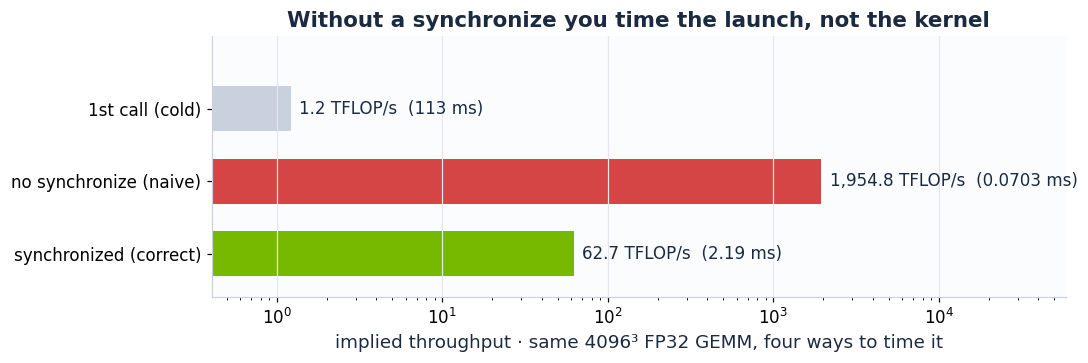

In [4]:
# ── Four different "timings" of the very same FP32 GEMM ──────────────────────
n_demo = 4096 if MEM_GB > 6 else 2048
A = cp.random.standard_normal((n_demo, n_demo), dtype=cp.float32)
B = cp.random.standard_normal((n_demo, n_demo), dtype=cp.float32)
C_ = cp.empty_like(A); gsync()
flops = 2.0 * n_demo**3

t0 = time.perf_counter(); cp.matmul(A, B, out=C_); gsync(); t_cold = time.perf_counter() - t0    # very first cuBLAS call
reps = 20
t0 = time.perf_counter()
for _ in range(reps): cp.matmul(A, B, out=C_)
t_naive = (time.perf_counter() - t0) / reps                                                      # NO synchronize
gsync()
t_sync = time_gpu_batch(lambda: cp.matmul(A, B, out=C_)).median                                  # events + sync

demo = pd.DataFrame({"measurement": ["1st call (cold)", "no synchronize (naive)", "synchronized (correct)"],
                     "seconds": [t_cold, t_naive, t_sync]})
demo["TFLOP/s"] = flops / demo.seconds / 1e12
fp32_peak = (PEAK_GFLOPS.get("FP32") or 0) / 1e3
demo["impossible?"] = (demo["TFLOP/s"] > fp32_peak * 1.02) if fp32_peak else False
save_df(demo, "00_timing_pitfalls")
SUMMARY["pitfalls"] = dict(n=n_demo, rows=demo.to_dict("records"))

fig, ax = plt.subplots(figsize=(10, 3.4))
cols = [GREY, RED, GREEN]
y = np.arange(len(demo))[::-1]
ax.barh(y, demo["TFLOP/s"], color=cols, height=0.62)
ax.set_xscale("log"); ax.set_yticks(y); ax.set_yticklabels(demo.measurement)
for yi, (tf, sec) in zip(y, zip(demo["TFLOP/s"], demo.seconds)):
    ax.text(tf * 1.12, yi, f"{tf:,.1f} TFLOP/s  ({sec * 1e3:.3g} ms)", va="center", fontsize=11, color=NAVY)
if fp32_peak:
    ax.axvline(fp32_peak, color=NAVY, ls="--", lw=1.6); ax.text(fp32_peak, 2.55, " FP32 datasheet peak", color=NAVY, fontsize=10, va="bottom")
ax.set_xlim(left=min(demo["TFLOP/s"]) / 3, right=max(demo["TFLOP/s"]) * 30)
ax.set_xlabel(f"implied throughput · same {n_demo}³ FP32 GEMM, four ways to time it")
ax.set_title("Without a synchronize you time the launch, not the kernel")
ax.set_ylim(-0.6, 3.0); ax.grid(axis="y", visible=False)
fig.tight_layout(); save_fig(fig, "00_timing_pitfalls"); plt.show()
del A, B, C_
cp.get_default_memory_pool().free_all_blocks()

# Part A · cuBLAS tour — dense GEMM

$C = A\,B$ with square $n\times n$ matrices: **$2n^3$ FLOP** on only $3n^2$ numbers → arithmetic intensity grows like $n$, so large GEMMs are **compute-bound**.

| Label | Inputs / outputs | Accumulate | Engine |
|---|---|---|---|
| **FP64** | float64 | FP64 | `cublasDgemm` — FP64 tensor cores on A100/H100 |
| **FP32** | float32 | FP32 | `cublasSgemm`, strict IEEE FP32 (CUDA cores) |
| **TF32** | float32 | FP32, inputs rounded to 10-bit mantissa | **`cublasGemmEx`** with `COMPUTE_32F_FAST_TF32` (Ampere+) |
| **FP16** | float16 | FP32 | **`cublasGemmEx`** mixed precision (tensor cores, Volta+) |

We call `cublasGemmEx` directly through CuPy's low-level bindings so the compute type is *explicit* — and we fall back to `cupy.matmul` if a self-test fails.

In [5]:
#@title cuBLAS GEMM backends + self-test { display-mode: "form" }
try:
    from cupy_backends.cuda.libs import cublas as _cublas_raw
except Exception:
    _cublas_raw = None

# cudaDataType_t: R_32F=0, R_64F=1, R_16F=2 · cublasComputeType_t: 16F=64, 32F=68, 64F=70, 32F_FAST_TF32=77
PREC = {
    "FP64": dict(dtype=np.float64, code=1, compute=70, host=np.float64, min_cc=(5, 0), tol=1e-10, desc="float64 → FP64 accumulate"),
    "FP32": dict(dtype=np.float32, code=0, compute=68, host=np.float32, min_cc=(5, 0), tol=1e-4,  desc="float32 → FP32 accumulate (CUDA cores)"),
    "TF32": dict(dtype=np.float32, code=0, compute=77, host=np.float32, min_cc=(8, 0), tol=2e-2,  desc="float32 in/out, TF32 tensor-core multiply"),
    "FP16": dict(dtype=np.float16, code=2, compute=68, host=np.float32, min_cc=(7, 0), tol=2e-2,  desc="float16 in/out → FP32 accumulate"),
}

def _gemm_ex(A, B, C, spec):
    # Row-major C = A @ B  ==  column-major C^T = B^T A^T  →  swap operands, swap m/n.
    m, k = A.shape; n = B.shape[1]
    h = cp.cuda.device.get_cublas_handle()
    _cublas_raw.setPointerMode(h, 0)                                   # host pointers for alpha / beta
    one, zero = np.ones((), spec["host"]), np.zeros((), spec["host"])
    _cublas_raw.gemmEx(h, 0, 0, n, m, k,
                       one.ctypes.data, B.data.ptr, spec["code"], n,
                       A.data.ptr, spec["code"], k,
                       zero.ctypes.data, C.data.ptr, spec["code"], n,
                       spec["compute"], -1)                            # -1 = CUBLAS_GEMM_DEFAULT

GEMM_BACKEND = {}      # precision → "cublasGemmEx" | "cupy.matmul" | None (unsupported)

def make_gemm(prec, A, B, C):
    spec = PREC[prec]
    if GEMM_BACKEND[prec] == "cublasGemmEx":
        return lambda: _gemm_ex(A, B, C, spec)
    return lambda: cp.matmul(A, B, out=C)

def validate_gemm_backends(n=1024):
    a = cp.random.standard_normal((n, n), dtype=cp.float32); b = cp.random.standard_normal((n, n), dtype=cp.float32)
    ref = cp.matmul(a.astype(cp.float64), b.astype(cp.float64))
    rows = []
    for prec, spec in PREC.items():
        if (CC_MAJOR, CC_MINOR) < spec["min_cc"]:
            GEMM_BACKEND[prec] = None
            rows.append(dict(precision=prec, backend="unsupported", rel_error=np.nan,
                             note=f"needs compute capability ≥ {spec['min_cc'][0]}.{spec['min_cc'][1]}"))
            continue
        A, B = a.astype(spec["dtype"]), b.astype(spec["dtype"]); C = cp.zeros((n, n), spec["dtype"])
        chosen, err, note = None, np.nan, ""
        if _cublas_raw is not None:
            try:
                _gemm_ex(A, B, C, spec); gsync()
                err = rel_err(C, ref)
                if err < spec["tol"]: chosen = "cublasGemmEx"
                else: note = f"GemmEx self-test failed (err={err:.1e})"
            except Exception as ex:
                note = f"GemmEx unavailable: {type(ex).__name__}"
        if chosen is None and prec != "TF32":
            C[...] = 0; cp.matmul(A, B, out=C); gsync(); err = rel_err(C, ref); chosen = "cupy.matmul"
        GEMM_BACKEND[prec] = chosen
        rows.append(dict(precision=prec, backend=chosen or "unavailable", rel_error=err, note=note or spec["desc"]))
    return pd.DataFrame(rows)

ACC_DF = validate_gemm_backends()

,precision,backend,rel. error ‖C−C₆₄‖/‖C₆₄‖,note
0,FP64,cublasGemmEx,0.00e+00,float64 → FP64 accumulate
1,FP32,cublasGemmEx,2.65e-07,float32 → FP32 accumulate (CUDA cores)
2,TF32,cublasGemmEx,2.94e-04,"float32 in/out, TF32 tensor-core multiply"
3,FP16,cublasGemmEx,3.60e-04,float16 in/out → FP32 accumulate


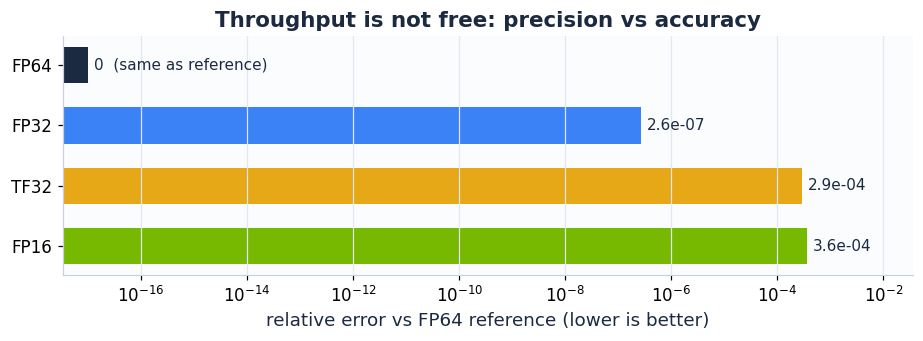

In [6]:
# ── Accuracy: what does each precision cost? (n = 1024, N(0,1) inputs, FP64 reference) ──
show_table(ACC_DF.rename(columns={"rel_error": "rel. error ‖C−C₆₄‖/‖C₆₄‖"}),
           {"rel. error ‖C−C₆₄‖/‖C₆₄‖": "{:.2e}"})
save_df(ACC_DF, "A1_gemm_accuracy")
SUMMARY["gemm_backends"] = ACC_DF.to_dict("records")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
d = ACC_DF.dropna(subset=["rel_error"]).copy()
d["err_plot"] = d.rel_error.clip(lower=1e-17)          # FP64-vs-FP64 can be bit-identical (error 0) → floor for the log axis
ax.barh(d.precision[::-1], d.err_plot[::-1], color=[PREC_COLORS[p] for p in d.precision[::-1]], height=0.6)
ax.set_xscale("log"); ax.set_xlabel("relative error vs FP64 reference (lower is better)")
for i, (pl, e) in enumerate(zip(d.err_plot[::-1], d.rel_error[::-1])): ax.text(pl * 1.3, i, f"{e:.1e}" if e > 0 else "0  (same as reference)", va="center", color=NAVY)
ax.set_title("Throughput is not free: precision vs accuracy"); ax.grid(axis="y", visible=False)
ax.set_xlim(left=d.err_plot.min() / 3, right=d.err_plot.max() * 100)
fig.tight_layout(); save_fig(fig, "A1_gemm_accuracy"); plt.show()

In [7]:
#@title GPU warm-up + GEMM sweep { display-mode: "form" }
def warm_up_gpu(seconds=2.0):
    n = 4096 if MEM_GB > 6 else 2048
    a = cp.random.standard_normal((n, n), dtype=cp.float32); b = cp.random.standard_normal((n, n), dtype=cp.float32)
    c = cp.empty_like(a); t0 = time.perf_counter()
    while time.perf_counter() - t0 < seconds: cp.matmul(a, b, out=c)
    gsync()

def _fits(n, itemsize):
    return (3 * itemsize + 4) * n * n < 0.85 * cp.cuda.runtime.memGetInfo()[0]

def sweep_gemm(sizes):
    rows = []
    for prec, spec in PREC.items():
        if GEMM_BACKEND.get(prec) is None: continue
        last_t, last_n = None, None
        for n in sizes:
            if last_t is not None and last_t * (n / last_n) ** 3 > MAX_POINT_SECONDS:
                print(f"  {prec}: stop before n={n} (predicted {last_t * (n / last_n) ** 3:.0f}s per call)"); break
            if not _fits(n, np.dtype(spec["dtype"]).itemsize):
                print(f"  {prec}: stop before n={n} (GPU memory)"); break
            try:
                A = cp.random.standard_normal((n, n), dtype=cp.float32).astype(spec["dtype"])
                B = cp.random.standard_normal((n, n), dtype=cp.float32).astype(spec["dtype"])
                C = cp.empty((n, n), spec["dtype"])
                t = time_gpu_batch(make_gemm(prec, A, B, C), min_time=0.3)
            except cp.cuda.memory.OutOfMemoryError:
                print(f"  {prec}: OOM at n={n}"); break
            finally:
                A = B = C = None; cp.get_default_memory_pool().free_all_blocks()
            fl = 2.0 * n**3
            peak = PEAK_GFLOPS.get(prec)
            rows.append(dict(precision=prec, backend=GEMM_BACKEND[prec], n=n, ms=t.median * 1e3,
                             gflops=fl / t.median / 1e9, gflops_best=fl / t.best / 1e9, gflops_worst=fl / t.worst / 1e9,
                             pct_peak=(100 * fl / t.median / 1e9 / peak) if peak else np.nan))
            last_t, last_n = t.median, n
    return pd.DataFrame(rows)

print("warming up the GPU …"); warm_up_gpu(2.0)
GEMM_DF = sweep_gemm(GEMM_SIZES)
save_df(GEMM_DF, "A2_gemm_sweep")
print(f"done · {len(GEMM_DF)} measurements")

warming up the GPU …
done · 32 measurements


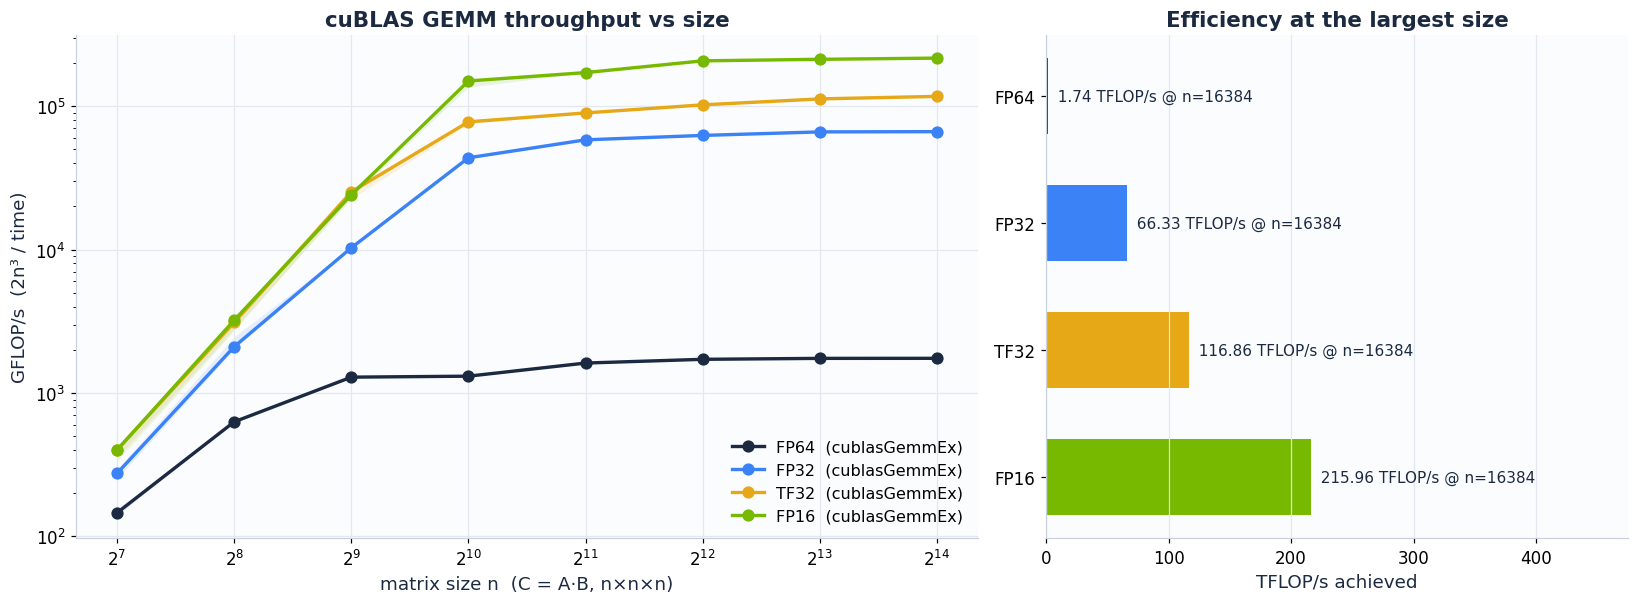

precision,FP64,FP32,TF32,FP16
n ↓ TFLOP/s →,,,,
128,0.15,0.28,0.40,0.40
256,0.63,2.10,3.10,3.22
512,1.29,10.29,25.25,24.10
1024,1.31,43.60,77.63,149.68
2048,1.62,58.18,89.61,171.18
4096,1.72,62.43,102.00,206.72
8192,1.74,66.08,112.22,211.90
16384,1.74,66.33,116.86,215.96


In [8]:
# ── GFLOP/s vs matrix size, against the card's peak ──────────────────────────
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw=dict(width_ratios=[1.55, 1]))
for prec in PREC:
    d = GEMM_DF[GEMM_DF.precision == prec]
    if d.empty: continue
    col = PREC_COLORS[prec]
    ax.fill_between(d.n, d.gflops_worst, d.gflops_best, color=col, alpha=0.12, lw=0)
    ax.plot(d.n, d.gflops, "-o", color=col, label=f"{prec}  ({d.backend.iloc[0]})")
_groups = {}                                      # precisions that share a peak (e.g. FP64 & FP32 on A100) get one label
for prec in PREC:
    pk = PEAK_GFLOPS.get(prec)
    if pk and prec in set(GEMM_DF.precision): _groups.setdefault(pk, []).append(prec)
for pk, ps in _groups.items():
    ax.axhline(pk, color=PREC_COLORS[ps[-1]], ls="--", lw=1.3, alpha=0.9)
    ax.text(GEMM_DF.n.min(), pk * 1.07, " / ".join(ps) + f" peak {pk / 1e3:,.3g} TFLOP/s", color=PREC_COLORS[ps[-1]], fontsize=9.5, va="bottom")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("matrix size n  (C = A·B, n×n×n)"); ax.set_ylabel("GFLOP/s  (2n³ / time)")
ax.set_title("cuBLAS GEMM throughput vs size"); ax.legend(loc="lower right")

# right: how much of the peak do we reach at the largest size per precision?
last = GEMM_DF.sort_values("n").groupby("precision").tail(1).set_index("precision").reindex([p for p in PREC if p in set(GEMM_DF.precision)])
have_peak = last.pct_peak.notna().any()
vals = last.pct_peak if have_peak else last.gflops / 1e3
ax2.barh(last.index[::-1], vals[::-1], color=[PREC_COLORS[p] for p in last.index[::-1]], height=0.6)
for i, p in enumerate(last.index[::-1]):
    v = vals[p]
    ax2.text(0 if np.isnan(v) else v, i, f"  {last.gflops[p] / 1e3:,.2f} TFLOP/s @ n={int(last.n[p])}" + (f"  ({v:.0f}% of peak)" if have_peak and not np.isnan(v) else ""),
             va="center", fontsize=10, color=NAVY)
ax2.set_xlabel("% of datasheet peak" if have_peak else "TFLOP/s achieved")
ax2.set_xlim(0, (max(vals.max() * 1.9, 100) if have_peak else vals.max() * 2.2))
ax2.set_title("Efficiency at the largest size"); ax2.grid(axis="y", visible=False)
fig.tight_layout(); save_fig(fig, "A2_gemm_throughput"); plt.show()

# table: TFLOP/s by size and precision
piv = GEMM_DF.pivot(index="n", columns="precision", values="gflops")[[p for p in PREC if p in set(GEMM_DF.precision)]] / 1e3
piv.index.name = "n  ↓   TFLOP/s →"
show_table(piv, {c: "{:,.2f}" for c in piv.columns}, grad=list(piv.columns))

In [9]:
# ── Part-A scorecard (auto-generated from the measurements) ──────────────────
best = GEMM_DF.groupby("precision").gflops.max() / 1e3          # TFLOP/s
pct = GEMM_DF.groupby("precision").pct_peak.max()
SUMMARY["gemm_best_tflops"] = best.to_dict(); SUMMARY["gemm_best_pct_peak"] = pct.to_dict()
items = []
for p in PREC:
    if p in best.index:
        sub = f"{pct[p]:.0f}% of {PEAK_GFLOPS[p] / 1e3:,.3g} TFLOP/s peak" if PEAK_GFLOPS.get(p) and not np.isnan(pct[p]) else "peak unknown"
        items.append((f"{p} · best", f"{best[p]:,.2f} TFLOP/s", sub))
    else:
        items.append((f"{p}", "n/a", "not supported on this GPU"))
cards(items)
if "FP32" in best.index and "TF32" in best.index: print(f"TF32 / FP32  = {best['TF32'] / best['FP32']:.1f}×")
if "FP32" in best.index and "FP16" in best.index: print(f"FP16 / FP32  = {best['FP16'] / best['FP32']:.1f}×")
if "FP64" in best.index and "FP32" in best.index: print(f"FP32 / FP64  = {best['FP32'] / best['FP64']:.1f}×")

TF32 / FP32  = 1.8×
FP16 / FP32  = 3.3×
FP32 / FP64  = 38.0×


# Part B · cuSPARSE on Matrix Market — SpMV on real matrices

Pipeline from the brief: **`.mtx` → CSR on host → copy to GPU → `cusparseSpMV`**.

SpMV does only **2 FLOP per stored non-zero** but must *read* `value (8 B) + column index (4 B)` for each one → **~0.16 FLOP/byte**: it is limited by **memory bandwidth**, not arithmetic.

$$\text{bytes per SpMV} \;\approx\; 12\,\text{nnz} + 4(n{+}1) + 8n\;(x) + 8n\;(y)\qquad\Longrightarrow\qquad \text{achieved GB/s} = \frac{\text{bytes}}{t}$$

(This is the *minimum* traffic; irregular matrices re-read `x` and therefore move more — so our GB/s is a conservative *effective* number.)

In [10]:
#@title SuiteSparse download / loader / synthetic fallback { display-mode: "form" }
SS_MIRRORS = ["https://sparse.tamu.edu/MM/{group}/{name}.tar.gz",
              "https://suitesparse-collection-website.herokuapp.com/MM/{group}/{name}.tar.gz"]

MATRIX_DIRS = [MTX, Path("..") / "matrices"]          # notebook in notebooks/ → finds ../matrices too

def _candidates(name):
    for d in MATRIX_DIRS:
        for rel in (f"{name}/{name}.mtx", f"{name}.mtx", f"{name}/{name}.mtx.gz", f"{name}.mtx.gz"):
            yield d / rel

def _find_local(name):
    return next((p for p in _candidates(name) if p.exists()), None)

def _download(url, dst):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as r, open(dst, "wb") as f: shutil.copyfileobj(r, f)

def fetch_matrix(spec):
    name = spec["name"]
    p = _find_local(name)
    if p: return p, f"local file {p}"
    out = MTX / name; out.mkdir(parents=True, exist_ok=True)
    if spec.get("url"):                                   # direct .mtx / .mtx.gz (e.g. NIST Matrix Market)
        dst = out / (f"{name}.mtx.gz" if spec["url"].endswith(".gz") else f"{name}.mtx")
        try:
            _download(spec["url"], dst); return dst, "downloaded (NIST Matrix Market)"
        except Exception as e:
            dst.unlink(missing_ok=True); raise RuntimeError(f"download failed ({type(e).__name__}: {e})")
    tgz = MTX / f"{name}.tar.gz"; last = None             # SuiteSparse Group/Name
    for tmpl in SS_MIRRORS:
        try:
            _download(tmpl.format(group=spec["group"], name=name), tgz); last = None; break
        except Exception as e:
            last = e; tgz.unlink(missing_ok=True)
    if last is not None: raise RuntimeError(f"download failed ({type(last).__name__}: {last})")
    with tarfile.open(tgz) as t:
        mem = [m for m in t.getmembers() if m.isfile() and m.name.endswith(".mtx")]
        mem = sorted(mem, key=lambda m: Path(m.name).name != f"{name}.mtx")[0]
        with t.extractfile(mem) as src, open(out / f"{name}.mtx", "wb") as dst: shutil.copyfileobj(src, dst)
    tgz.unlink(missing_ok=True)
    return out / f"{name}.mtx", "downloaded (SuiteSparse)"

def as_int32_csr(A):
    A = sp.csr_matrix(A, dtype=np.float64)
    A.sum_duplicates(); A.sort_indices()
    if A.nnz < 2**31 - 1:
        A.indices = A.indices.astype(np.int32, copy=False); A.indptr = A.indptr.astype(np.int32, copy=False)
    return A

def poisson2d(g):
    T = sp.diags([-1.0, 2.0, -1.0], [-1, 0, 1], shape=(g, g), format="csr")
    I = sp.identity(g, format="csr")
    return as_int32_csr(sp.kron(I, T) + sp.kron(T, I))

def banded_spd(n, hb=32):
    offs = [o for o in range(-hb, hb + 1) if o != 0]
    diags = [np.full(n - abs(o), -1.0 / (1 + abs(o))) for o in offs]
    main = 2 * sum(1.0 / (1 + k) for k in range(1, hb + 1)) + 1.0
    return as_int32_csr(sp.diags(diags + [np.full(n, main)], offs + [0], shape=(n, n), format="csr"))

def powerlaw_graph(n, seed=0):
    rng = np.random.default_rng(seed)
    deg = np.minimum(rng.zipf(2.3, n), 5000)
    rows = np.repeat(np.arange(n, dtype=np.int64), deg)
    cols = rng.zipf(1.6, rows.size) % n
    return as_int32_csr(sp.csr_matrix((rng.random(rows.size) + 0.1, (rows, cols)), shape=(n, n)))

STANDINS = {"ecology2": lambda: poisson2d(1000), "cant": lambda: banded_spd(62451, 32),
            "webbase-1M": lambda: powerlaw_graph(1_000_005), "s3dkq4m2": lambda: banded_spd(90449, 26),
            "memplus": lambda: powerlaw_graph(17758)}

def synth_standin(name):
    if name not in STANDINS:
        raise RuntimeError(f"no synthetic stand-in defined for '{name}'")
    return STANDINS[name]()

def load_matrix(spec):
    name = spec["name"]
    try:
        path, how = fetch_matrix(spec)
        t0 = time.perf_counter(); A = as_int32_csr(mmread(str(path)))       # mmread reads .mtx and .mtx.gz
        return A, how, time.perf_counter() - t0
    except Exception as e:
        where = "\n      ".join(str(p.resolve()) for p in _candidates(name))
        msg = (f"⚠ {name}: real matrix not available — {str(e)[:120]}\n"
               f"  working directory: {Path.cwd()}\n  looked for:\n      {where}")
        if not (ALLOW_SYNTHETIC_FALLBACK and name in STANDINS):
            raise RuntimeError(msg + "\n  → put the .mtx file in one of these places and re-run.")
        print(msg + "\n  → using a clearly-labelled SYNTHETIC stand-in (NOT the real matrix).")
        return synth_standin(name), "SYNTHETIC stand-in", 0.0

def is_symmetric(A):
    return A.shape[0] == A.shape[1] and (A != A.T).nnz == 0

def spmv_bytes(n, nnz):
    return 12.0 * nnz + 4.0 * (n + 1) + 16.0 * n          # values+indices, row pointers, read x, write y

In [11]:
# ── Step 1+2: .mtx → CSR on host ─────────────────────────────────────────────
HOST, MAT_SPD, MAT_SRC, info = {}, {}, {}, []
for spec in MATRICES:
    t0 = time.perf_counter()
    A, src, t_read = load_matrix(spec)
    name = spec["name"]; HOST[name] = A; MAT_SPD[name] = spec["spd"]; MAT_SRC[name] = src
    rl = np.diff(A.indptr)
    info.append(dict(matrix=name, source=src, n=A.shape[0], nnz=A.nnz, nnz_per_row=A.nnz / A.shape[0], max_row=int(rl.max()),
                     csr_MB=(A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 2**20,
                     symmetric=bool(is_symmetric(A)), read_s=t_read, note=spec["note"]))
    print(f"  {name:<12s} {A.shape[0]:>9,} × {A.shape[1]:<9,} nnz={A.nnz:>10,}   [{src}]  {time.perf_counter() - t0:.1f}s")
INFO_DF = pd.DataFrame(info); save_df(INFO_DF, "B1_matrix_info"); SUMMARY["matrices"] = INFO_DF.to_dict("records")
show_table(INFO_DF.set_index("matrix"), {"n": "{:,}", "nnz": "{:,}", "nnz_per_row": "{:.1f}", "csr_MB": "{:.0f}", "read_s": "{:.1f}"})
if any("SYNTHETIC" in s for s in MAT_SRC.values()):
    display(HTML('<div style="padding:10px 14px;border-radius:8px;background:#FFF3CD;color:#7A5B00;font-family:sans-serif">'
                 '⚠ At least one matrix is a <b>synthetic stand-in</b> (download failed). Results below are labelled accordingly — '
                 'fix the network or drop the .mtx files into <code>./matrices/</code> and re-run for the real thing.</div>'))

  s3dkq4m2        90,449 × 90,449    nnz= 4,820,891   [local file ../matrices/s3dkq4m2/s3dkq4m2.mtx]  0.4s
⚠ ecology2: real matrix not available — download failed (URLError: <urlopen error [Errno 101] Network is unreachable>)
  working directory: /root/autodl-tmp/gpu-kernels-hackathon/notebooks
  looked for:
      /root/autodl-tmp/gpu-kernels-hackathon/notebooks/matrices/ecology2/ecology2.mtx
      /root/autodl-tmp/gpu-kernels-hackathon/notebooks/matrices/ecology2.mtx
      /root/autodl-tmp/gpu-kernels-hackathon/notebooks/matrices/ecology2/ecology2.mtx.gz
      /root/autodl-tmp/gpu-kernels-hackathon/notebooks/matrices/ecology2.mtx.gz
      /root/autodl-tmp/gpu-kernels-hackathon/matrices/ecology2/ecology2.mtx
      /root/autodl-tmp/gpu-kernels-hackathon/matrices/ecology2.mtx
      /root/autodl-tmp/gpu-kernels-hackathon/matrices/ecology2/ecology2.mtx.gz
      /root/autodl-tmp/gpu-kernels-hackathon/matrices/ecology2.mtx.gz
  → using a clearly-labelled SYNTHETIC stand-in (NOT the real matr

,source,n,nnz,nnz_per_row,max_row,csr_MB,symmetric,read_s,note
matrix,,,,,,,,,
s3dkq4m2,local file ../matrices/s3dkq4m2/s3dkq4m2.mtx,"90,449","4,820,891",53.3,54,56,True,0.3,FEM cylindrical shell · SPD · ~53 nnz/row
ecology2,SYNTHETIC stand-in,"1,000,000","4,996,000",5.0,5,61,True,0.0,5-point grid stencil · ~5 nnz/row
memplus,local file ../matrices/memplus/memplus.mtx,"17,758","126,150",7.1,574,2,False,0.0,memory circuit · unsymmetric · irregular rows


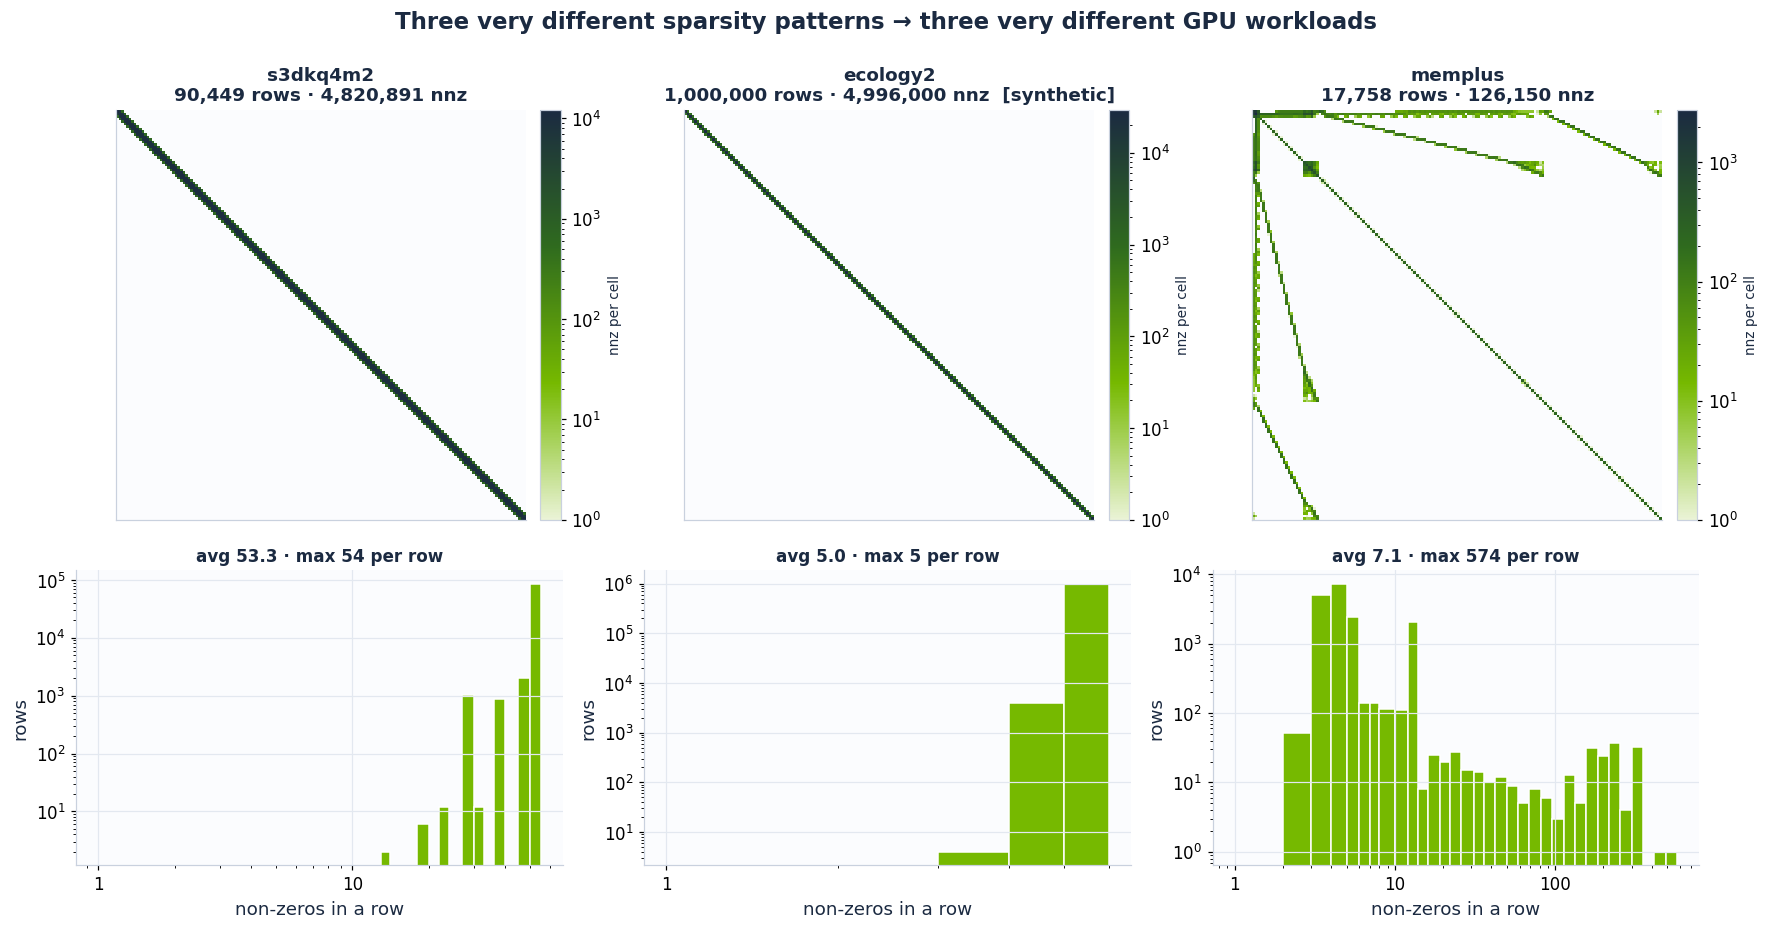

In [12]:
# ── What do these matrices look like? (non-zero density map + row-length distribution) ──
def density_map(A, B=160):
    n, m = A.shape
    rows = np.repeat(np.arange(n, dtype=np.int64), np.diff(A.indptr))
    return np.bincount((rows * B // n) * B + (A.indices.astype(np.int64) * B // m), minlength=B * B).reshape(B, B)

k = len(HOST)
fig, axes = plt.subplots(2, k, figsize=(5.4 * k, 8.4), squeeze=False, gridspec_kw=dict(height_ratios=[1.25, 0.9]))
for j, (name, A) in enumerate(HOST.items()):
    H = np.ma.masked_equal(density_map(A), 0)
    ax = axes[0, j]; im = ax.imshow(H, cmap=DENS_CMAP, norm=LogNorm(vmin=1), interpolation="nearest")
    ax.set_title(f"{name}\n{A.shape[0]:,} rows · {A.nnz:,} nnz" + ("  [synthetic]" if "SYNTH" in MAT_SRC[name] else ""), fontsize=12)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03); cb.set_label("nnz per cell", fontsize=9)
    rl = np.diff(A.indptr); rl = rl[rl > 0]
    bins = np.unique(np.round(np.logspace(0, np.log10(rl.max() + 1), 40)).astype(int))
    ax = axes[1, j]; ax.hist(rl, bins=bins, color=GREEN, edgecolor="white")
    ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax, "x"); ax.set_xlabel("non-zeros in a row"); ax.set_ylabel("rows")
    ax.set_title(f"avg {A.nnz / A.shape[0]:.1f} · max {int(np.diff(A.indptr).max()):,} per row", fontsize=11)
fig.suptitle("Three very different sparsity patterns → three very different GPU workloads", fontsize=15, fontweight="bold", color=NAVY, y=1.0)
fig.tight_layout(); save_fig(fig, "B1_matrix_structure"); plt.show()

# export the structure (128×128 non-zero density map + stats) so the slides can draw the real matrices
STRUCT = [dict(matrix=name, source=MAT_SRC[name], n=int(A.shape[0]), nnz=int(A.nnz), nnz_per_row=A.nnz / A.shape[0],
               max_row=int(np.diff(A.indptr).max()), spd=bool(MAT_SPD[name]), density=density_map(A, 128).tolist(),
               zoom_rows=int(min(3000, A.shape[0])), zoom=density_map(A[:min(3000, A.shape[0]), :min(3000, A.shape[0])], 128).tolist())
          for name, A in HOST.items()]
with open(DATA / "B1_structure.json", "w") as f: json.dump(STRUCT, f)

In [13]:
#@title GPU sparse backends: pre-built cusparseSpMV + cuBLAS BLAS-1 (with self-tests) { display-mode: "form" }
try:
    from cupy import cusparse as _cp_cusparse
    from cupy_backends.cuda.libs import cusparse as _cusparse_raw
except Exception:
    _cp_cusparse = _cusparse_raw = None

class _RawSpMV:
    # y = A x via the generic cusparseSpMV API. Descriptors + workspace are built ONCE, so repeated calls
    # time the library kernel instead of CuPy's per-call Python/descriptor overhead.
    def __init__(self, A_d, x_d, y_d):
        self.keep = (A_d, x_d, y_d)
        self.h = cp.cuda.device.get_cusparse_handle()
        self.alpha, self.beta = np.ones((), np.float64), np.zeros((), np.float64)
        self.mat = _cp_cusparse.SpMatDescriptor.create(A_d)
        self.vx = _cp_cusparse.DnVecDescriptor.create(x_d)
        self.vy = _cp_cusparse.DnVecDescriptor.create(y_d)
        size = _cusparse_raw.spMV_bufferSize(self.h, 0, self.alpha.ctypes.data, self.mat.desc, self.vx.desc,
                                             self.beta.ctypes.data, self.vy.desc, 1, 0)      # 1 = CUDA_R_64F, 0 = ALG_DEFAULT
        self.buf = cp.empty(max(int(size), 1), dtype=cp.int8)
    def __call__(self):
        _cusparse_raw.spMV(self.h, 0, self.alpha.ctypes.data, self.mat.desc, self.vx.desc,
                           self.beta.ctypes.data, self.vy.desc, 1, 0, self.buf.data.ptr)

RAW_SPMV_OK = False
if _cp_cusparse is not None and _cusparse_raw is not None:
    try:
        _A = as_int32_csr(sp.random(3000, 3000, density=0.01, format="csr", random_state=1) + sp.identity(3000))
        _x = np.random.default_rng(0).random(3000)
        _Ad, _xd, _yd = cpx_sparse.csr_matrix(_A), cp.asarray(_x), cp.zeros(3000)
        _op = _RawSpMV(_Ad, _xd, _yd); _op(); gsync()
        RAW_SPMV_OK = bool(np.allclose(cp.asnumpy(_yd), _A.dot(_x), rtol=1e-10))
    except Exception as ex:
        print("raw cusparseSpMV path unavailable:", type(ex).__name__, str(ex)[:80])

def make_spmv(A_d, x_d, y_d):
    if RAW_SPMV_OK:
        try: return _RawSpMV(A_d, x_d, y_d), "cusparseSpMV (pre-built descriptors)"
        except Exception: pass
    def f(): y_d[...] = A_d.dot(x_d)
    return f, "CuPy dispatch  A.dot(x)  (includes host overhead)"

def _select_blas1():
    try:
        v, w = cp.arange(1, 5, dtype=cp.float64), cp.ones(4, dtype=cp.float64)
        assert abs(float(cp_cublas.dot(v, w)) - 10.0) < 1e-12
        cp_cublas.axpy(2.0, v, w); assert np.allclose(cp.asnumpy(w), [3, 5, 7, 9])
        cp_cublas.scal(0.5, w);    assert np.allclose(cp.asnumpy(w), [1.5, 2.5, 3.5, 4.5])
        return "cuBLAS  (Ddot · Daxpy · Dscal)", (lambda a, b: float(cp_cublas.dot(a, b))), cp_cublas.axpy, cp_cublas.scal
    except Exception:
        def axpy(al, x, y): y += al * x
        def scal(al, x): x *= al
        return "CuPy elementwise (fallback)", (lambda a, b: float(cp.dot(a, b))), axpy, scal
BLAS1_NAME, B1_dot, B1_axpy, B1_scal = _select_blas1()
SPMV_PATH = "cusparseSpMV (pre-built descriptors)" if RAW_SPMV_OK else "CuPy dispatch A.dot(x)"
SUMMARY["backends"] = dict(spmv=SPMV_PATH, blas1=BLAS1_NAME, gemm={k: v for k, v in GEMM_BACKEND.items()})
print(f"SpMV path : {SPMV_PATH}\nBLAS-1    : {BLAS1_NAME}")

SpMV path : cusparseSpMV (pre-built descriptors)
BLAS-1    : cuBLAS  (Ddot · Daxpy · Dscal)


In [14]:
#@title SpMV benchmark on GPU and CPU { display-mode: "form" }
def to_gpu(A_h, x_h):
    cp.get_default_memory_pool().free_all_blocks(); gsync()
    t0 = time.perf_counter()
    A_d = cpx_sparse.csr_matrix(A_h); x_d = cp.asarray(x_h); gsync()
    return A_d, x_d, time.perf_counter() - t0

_free = cp.cuda.runtime.memGetInfo()[0]
FLUSH_BYTES = int(min(max(4 * L2_BYTES, 512 * 2**20), 0.25 * _free))
FLUSH = cp.empty(FLUSH_BYTES // 8, dtype=cp.float64)           # written before each "cold" call → evicts L2

rng = np.random.default_rng(0); rows = []
for name, A_h in HOST.items():
    n, nnz = A_h.shape[0], A_h.nnz
    x_h = rng.random(n)
    t_cpu = time_wall(lambda: A_h.dot(x_h), min_time=0.5, min_reps=5, max_reps=100, warmup=2)
    y_ref = A_h.dot(x_h)
    A_d, x_d, t_h2d = to_gpu(A_h, x_h); y_d = cp.zeros(n)
    op, mode = make_spmv(A_d, x_d, y_d); op(); gsync()
    err = float(np.linalg.norm(cp.asnumpy(y_d) - y_ref) / np.linalg.norm(y_ref))
    t_cold = time_gpu_flush(op, FLUSH)
    t_warm = time_gpu_batch(op, min_time=0.3)
    nbytes = spmv_bytes(n, nnz)
    rows.append(dict(matrix=name, source=MAT_SRC[name], n=n, nnz=nnz, bytes_MB=nbytes / 2**20,
                     cpu_ms=t_cpu.median * 1e3, gpu_cold_ms=t_cold.median * 1e3, gpu_warm_ms=t_warm.median * 1e3,
                     speedup=t_cpu.median / t_cold.median,
                     gpu_GBs=nbytes / t_cold.median / 1e9, gpu_warm_GBs=nbytes / t_warm.median / 1e9, cpu_GBs=nbytes / t_cpu.median / 1e9,
                     pct_stream=100 * nbytes / t_cold.median / 1e9 / STREAM_BW,
                     pct_spec=(100 * nbytes / t_cold.median / 1e9 / PEAK_BW) if PEAK_BW else np.nan,
                     gpu_GFLOPs=2.0 * nnz / t_cold.median / 1e9, cpu_GFLOPs=2.0 * nnz / t_cpu.median / 1e9,
                     h2d_ms=t_h2d * 1e3, breakeven_spmv=(t_h2d / (t_cpu.median - t_cold.median)) if t_cpu.median > t_cold.median else np.inf,
                     rel_err=err, spmv_path=mode))
    print(f"  {name:<12s} CPU {t_cpu.median * 1e3:8.2f} ms | GPU {t_cold.median * 1e3:7.3f} ms | {nbytes / t_cold.median / 1e9:7.1f} GB/s | err {err:.1e}")
    del A_d, x_d, y_d, op; cp.get_default_memory_pool().free_all_blocks()
SPMV_DF = pd.DataFrame(rows); save_df(SPMV_DF, "B2_spmv_results"); SUMMARY["spmv"] = SPMV_DF.to_dict("records")

  s3dkq4m2     CPU     2.44 ms | GPU   0.066 ms |   910.8 GB/s | err 3.8e-16
  ecology2     CPU     3.68 ms | GPU   0.078 ms |  1027.3 GB/s | err 1.4e-16
  memplus      CPU     0.08 ms | GPU   0.016 ms |   114.1 GB/s | err 3.6e-16


,n,nnz,CPU ms,GPU ms,speed-up ×,GPU GB/s,% of STREAM,% of datasheet,CPU GB/s,GPU GFLOP/s,H2D ms,break-even #SpMV,rel. err
matrix,,,,,,,,,,,,,
s3dkq4m2,"90,449","4,820,891",2.44,0.066,37.3,911,58%,51%,24.4,147.2,37.3,15.7,3.8e-16
ecology2,"1,000,000","4,996,000",3.68,0.078,47.3,1027,65%,57%,21.7,128.4,10.9,3.03,1.4e-16
memplus,"17,758","126,150",0.08,0.016,5.2,114,7%,6%,22.0,15.4,0.8,11.5,3.6e-16


SpMV path: cusparseSpMV (pre-built descriptors)   ·   GPU timings: kernel-only, L2 flushed, data resident (H2D listed separately)   ·   CPU: SciPy CSR, single thread


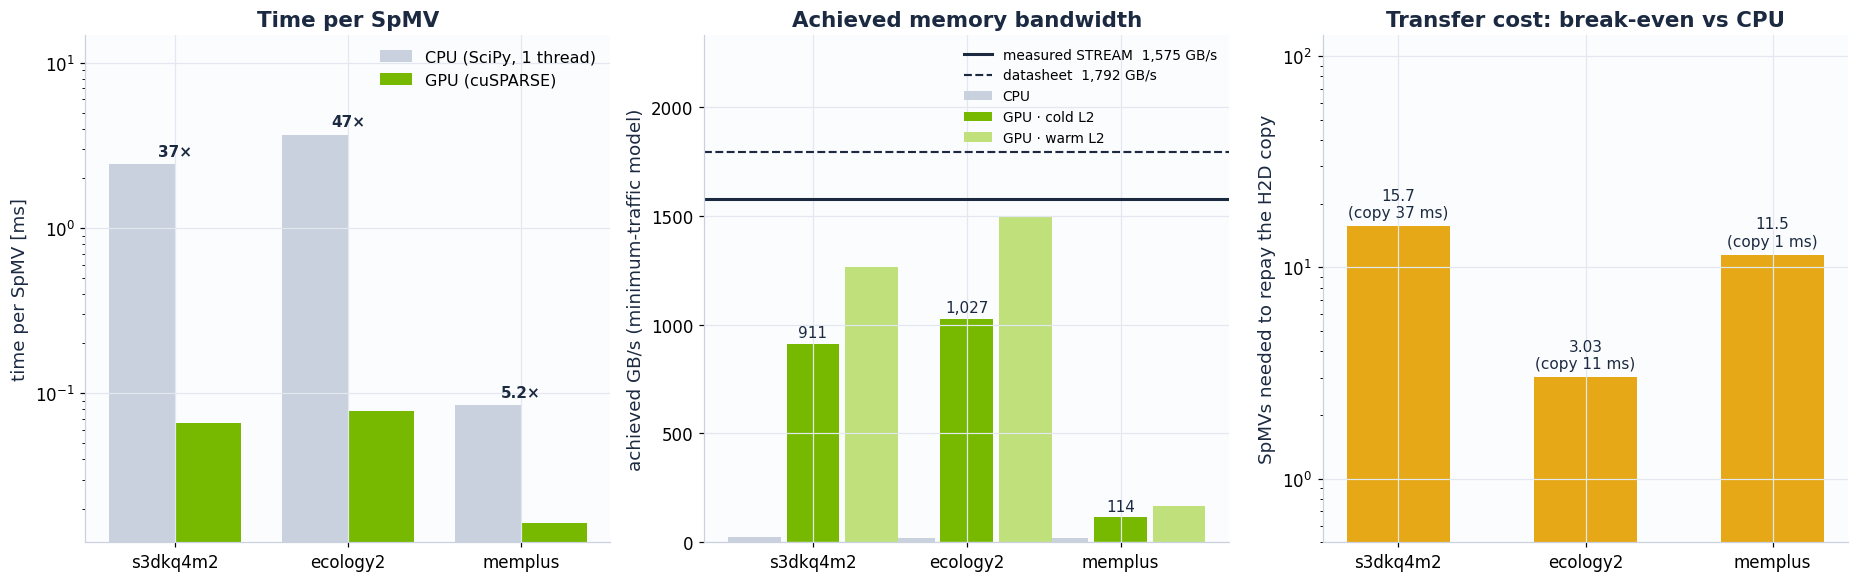

In [15]:
# ── Results table ────────────────────────────────────────────────────────────
t = SPMV_DF.set_index("matrix")
disp = pd.DataFrame({"n": t.n, "nnz": t.nnz, "CPU ms": t.cpu_ms, "GPU ms": t.gpu_cold_ms, "speed-up ×": t.speedup,
                     "GPU GB/s": t.gpu_GBs, "% of STREAM": t.pct_stream, "% of datasheet": t.pct_spec, "CPU GB/s": t.cpu_GBs,
                     "GPU GFLOP/s": t.gpu_GFLOPs, "H2D ms": t.h2d_ms, "break-even #SpMV": t.breakeven_spmv, "rel. err": t.rel_err})
show_table(disp, {"n": "{:,}", "nnz": "{:,}", "CPU ms": "{:.2f}", "GPU ms": "{:.3f}", "speed-up ×": "{:.1f}", "GPU GB/s": "{:.0f}",
                  "% of STREAM": "{:.0f}%", "% of datasheet": "{:.0f}%", "CPU GB/s": "{:.1f}", "GPU GFLOP/s": "{:.1f}",
                  "H2D ms": "{:.1f}", "break-even #SpMV": "{:.3g}", "rel. err": "{:.1e}"}, grad=["speed-up ×", "GPU GB/s"])
print(f"SpMV path: {SPMV_PATH}   ·   GPU timings: kernel-only, L2 flushed, data resident (H2D listed separately)   ·   CPU: SciPy CSR, single thread")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
x = np.arange(len(t)); w = 0.38
ax = axes[0]
ax.bar(x - w / 2, t.cpu_ms, w, color=GREY, label="CPU (SciPy, 1 thread)"); ax.bar(x + w / 2, t.gpu_cold_ms, w, color=GREEN, label="GPU (cuSPARSE)")
for i, (c, g, s) in enumerate(zip(t.cpu_ms, t.gpu_cold_ms, t.speedup)): ax.text(i, max(c, g) * 1.12, fx(s), ha="center", fontweight="bold", color=NAVY)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_ylabel("time per SpMV [ms]"); ax.set_title("Time per SpMV"); ax.legend(); ax.set_ylim(top=t.cpu_ms.max() * 4)

ax = axes[1]
ax.bar(x - w, t.cpu_GBs, w * 0.9, color=GREY, label="CPU"); ax.bar(x, t.gpu_GBs, w * 0.9, color=GREEN, label="GPU · cold L2"); ax.bar(x + w, t.gpu_warm_GBs, w * 0.9, color="#BFE07A", label="GPU · warm L2")
ax.axhline(STREAM_BW, color=NAVY, lw=2, label=f"measured STREAM  {STREAM_BW:,.0f} GB/s")
if PEAK_BW: ax.axhline(PEAK_BW, color=NAVY, lw=1.4, ls="--", label=f"datasheet  {PEAK_BW:,.0f} GB/s")
for i, v in enumerate(t.gpu_GBs): ax.text(i, v + STREAM_BW * 0.02, f"{v:,.0f}", ha="center", fontsize=10, color=NAVY)
ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_ylabel("achieved GB/s (minimum-traffic model)"); ax.set_title("Achieved memory bandwidth"); ax.legend(fontsize=9, loc="upper right")
ax.set_ylim(0, max(STREAM_BW, PEAK_BW or 0, t.gpu_warm_GBs.max()) * 1.3)

ax = axes[2]
be = t.breakeven_spmv.replace(np.inf, np.nan)
ax.set_xticks(x); ax.set_xticklabels(t.index); ax.set_title("Transfer cost: break-even vs CPU")
if be.notna().any():
    ax.bar(x, be.fillna(0), 0.55, color=ORANGE); ax.set_yscale("log")
    ax.set_ylim(bottom=min(be.min() / 2, 0.5), top=max(be.max(), 10) * 8); ax.set_ylabel("SpMVs needed to repay the H2D copy")
    for i, (b_, h) in enumerate(zip(t.breakeven_spmv, t.h2d_ms)):
        if np.isinf(b_): ax.text(i, 0.04, f"never\n(copy {h:.0f} ms)", transform=ax.get_xaxis_transform(), ha="center", fontsize=10, color=RED)
        else: ax.annotate(f"{b_:.3g}\n(copy {h:.0f} ms)", (i, b_), xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=10, color=NAVY)
else:
    ax.text(0.5, 0.5, "GPU never faster than the CPU here\n→ no break-even point", transform=ax.transAxes, ha="center", va="center", fontsize=12, color=RED)
    ax.set_yticks([])
fig.tight_layout(); save_fig(fig, "B2_spmv_results"); plt.show()

# The roofline story

Plot **achieved GFLOP/s** against **arithmetic intensity** (FLOP per byte of DRAM traffic), both in FP64:

* the **sloped roof** is memory bandwidth × intensity — SpMV lives here;
* the **flat roof** is the FP64 compute peak — large GEMM lives here;
* the **ridge point** (peak ÷ bandwidth) is the intensity needed before a kernel can become compute-bound.

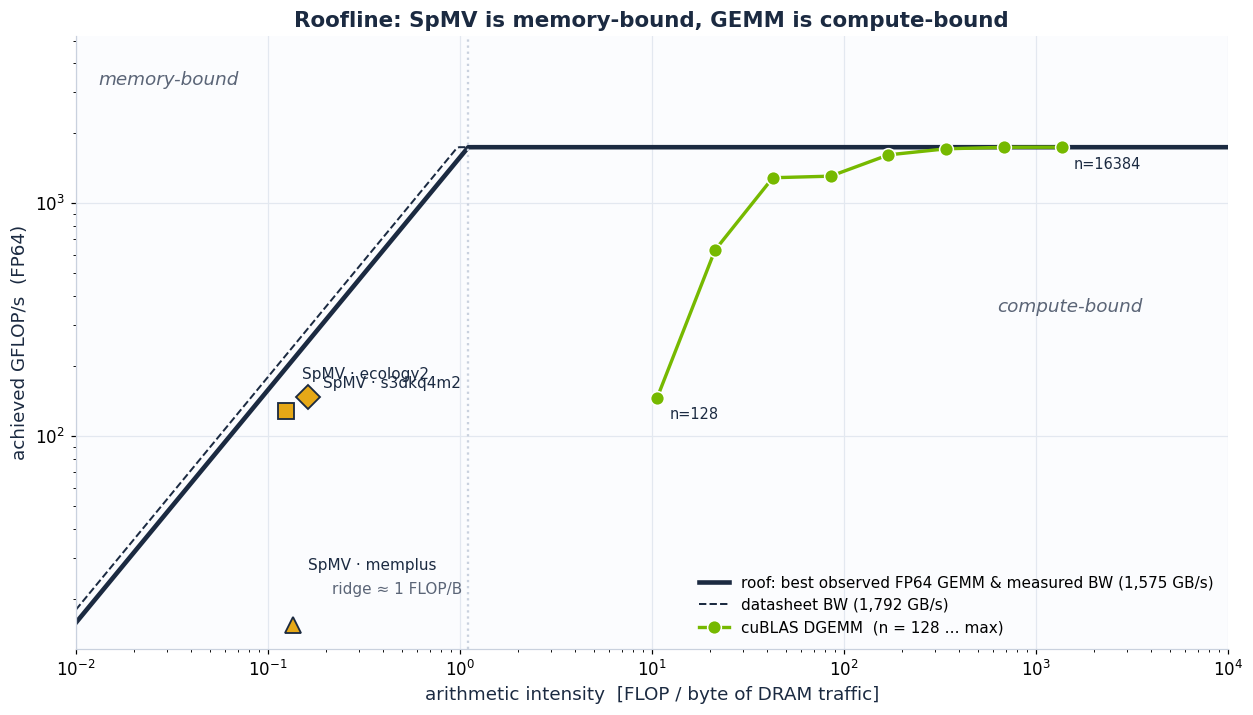

In [16]:
# ── Roofline: GEMM (FP64) and SpMV on one chart ──────────────────────────────
g64 = GEMM_DF[GEMM_DF.precision == "FP64"]
peak64 = PEAK_GFLOPS.get("FP64") or (g64.gflops.max() if len(g64) else np.nan)
peak_lbl = "FP64 datasheet peak" if PEAK_GFLOPS.get("FP64") else "best observed FP64 GEMM"
ai = np.logspace(-2, 4, 500)

fig, ax = plt.subplots(figsize=(11.5, 6.6))
ax.plot(ai, np.minimum(peak64, ai * STREAM_BW), color=NAVY, lw=3, label=f"roof: {peak_lbl} & measured BW ({STREAM_BW:,.0f} GB/s)")
if PEAK_BW: ax.plot(ai, np.minimum(peak64, ai * PEAK_BW), color=NAVY, lw=1.3, ls="--", label=f"datasheet BW ({PEAK_BW:,.0f} GB/s)")
ridge = peak64 / STREAM_BW
ax.axvline(ridge, color=GREY, ls=":", lw=1.5); ax.text(ridge / 1.08, peak64 * 0.012, f"ridge ≈ {ridge:.0f} FLOP/B", color=SLATE, fontsize=10, ha="right")
if len(g64):
    ax.plot(g64.n / 12.0, g64.gflops, "-o", color=GREEN, ms=9, mec="white", label="cuBLAS DGEMM  (n = 128 … max)")
    for _, r in g64.iloc[[0, -1]].iterrows(): ax.annotate(f"n={int(r.n)}", (r.n / 12.0, r.gflops), textcoords="offset points", xytext=(8, -14), fontsize=9.5, color=NAVY)
mk = ["D", "s", "^", "v", "P"]
for i, (_, r) in enumerate(SPMV_DF.iterrows()):
    a_i = 2.0 * r.nnz / (r.bytes_MB * 2**20)
    ax.plot(a_i, r.gpu_GFLOPs, mk[i % 5], color=ORANGE, ms=11, mec=NAVY, mew=1.2)
    ax.annotate(f"SpMV · {r.matrix}", (a_i, r.gpu_GFLOPs), textcoords="offset points", xytext=(10, 6 + 15 * i), fontsize=10, color=NAVY)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1e-2, 1e4); ax.set_ylim(top=peak64 * 3)
ax.set_xlabel("arithmetic intensity  [FLOP / byte of DRAM traffic]"); ax.set_ylabel("achieved GFLOP/s  (FP64)")
ax.set_title("Roofline: SpMV is memory-bound, GEMM is compute-bound"); ax.legend(loc="lower right", fontsize=10)
ax.text(0.02, 0.92, "memory-bound", transform=ax.transAxes, color=SLATE, fontsize=12, style="italic")
ax.text(0.80, 0.55, "compute-bound", transform=ax.transAxes, color=SLATE, fontsize=12, style="italic")
fig.tight_layout(); save_fig(fig, "B3_roofline"); plt.show()
SUMMARY["roofline"] = dict(peak64_gflops=float(peak64), peak_label=peak_lbl, stream_bw=float(STREAM_BW), ridge_flop_per_byte=float(ridge))

# Part C (stretch) · Conjugate Gradient on the GPU

CG solves $A x = b$ for symmetric positive-definite $A$. Each iteration is **one SpMV + two dot products + three axpy-type updates**:

```
Ap = A p              # cusparseSpMV
α  = (r·r) / (p·Ap)   # cuBLAS dot  (→ host scalar: a sync point)
x += α p ;  r -= α Ap # cuBLAS axpy
β  = (r·r)_new / (r·r)
p  = r + β p          # cuBLAS scal + axpy
```

Two questions from the brief:

1. **At what problem size does the GPU win?** Small problems are *latency-bound*: ≈ 7 kernel launches and 2 host syncs per iteration cost tens of µs no matter how small the vectors are.
2. **What does the transfer cost do to that answer?** We report kernel-only **and** end-to-end (copy A and b up, copy x back).

*Scaling study:* 2-D Poisson (5-point stencil, SPD), grid $g\times g$ → $n=g^2$, fixed iteration count so CPU and GPU do identical work.
*Real matrices:* CG on the SPD SuiteSparse matrices with an iteration cap.

In [17]:
#@title CG implementations (CPU reference + GPU) and validation { display-mode: "form" }
def cg_cpu(A, b, maxit, tol=0.0):
    x = np.zeros_like(b); r = b.copy(); p = b.copy()
    rr = float(r @ r); bnorm = math.sqrt(rr); its = 0
    for _ in range(maxit):
        Ap = A.dot(p)
        pAp = float(p @ Ap)
        if pAp == 0.0: break
        alpha = rr / pAp
        x += alpha * p
        r -= alpha * Ap
        rr_new = float(r @ r); its += 1
        if math.sqrt(rr_new) <= tol * bnorm: rr = rr_new; break
        p *= rr_new / rr
        p += r
        rr = rr_new
    return x, its, math.sqrt(rr) / bnorm

def cg_gpu(A_d, b_d, maxit, tol=0.0):
    n = b_d.size
    x = cp.zeros(n, dtype=cp.float64); r = b_d.copy(); p = b_d.copy(); Ap = cp.empty(n, dtype=cp.float64)
    spmv, _ = make_spmv(A_d, p, Ap)                      # descriptors bound to p / Ap (updated in place)
    rr = B1_dot(r, r); bnorm = math.sqrt(rr); its = 0
    for _ in range(maxit):
        spmv()                                           # Ap = A p        (cuSPARSE)
        pAp = B1_dot(p, Ap)                              # p·Ap            (cuBLAS dot  → host sync)
        if pAp == 0.0: break
        alpha = rr / pAp
        B1_axpy(alpha, p, x)                             # x += α p        (cuBLAS axpy)
        B1_axpy(-alpha, Ap, r)                           # r -= α Ap       (cuBLAS axpy)
        rr_new = B1_dot(r, r); its += 1                  # r·r             (cuBLAS dot  → host sync)
        if math.sqrt(rr_new) <= tol * bnorm: rr = rr_new; break
        B1_scal(rr_new / rr, p)                          # p *= β
        B1_axpy(1.0, r, p)                               # p += r
        rr = rr_new
    return x, its, math.sqrt(rr) / bnorm

def gpu_e2e(A_h, b_h, maxit, tol=0.0, reps=3):
    # End-to-end: cold memory pool → copy A,b up → solve → copy x back. Medians of each phase.
    comp = []
    for _ in range(reps):
        cp.get_default_memory_pool().free_all_blocks(); gsync()
        t0 = time.perf_counter()
        A_d = cpx_sparse.csr_matrix(A_h); b_d = cp.asarray(b_h); gsync()
        t1 = time.perf_counter()
        x_d, its, res = cg_gpu(A_d, b_d, maxit, tol); gsync()
        t2 = time.perf_counter()
        x_h = cp.asnumpy(x_d)
        t3 = time.perf_counter()
        comp.append((t1 - t0, t2 - t1, t3 - t2))
        del A_d, b_d, x_d
    med = np.median(np.array(comp), axis=0)
    return dict(h2d=float(med[0]), solve=float(med[1]), d2h=float(med[2]), its=its, res=res, x=x_h)

def crossover(ns, s):
    ns, s = np.asarray(ns, float), np.asarray(s, float)
    if np.all(s >= 1): return dict(kind="always", n=float(ns[0]))
    if np.all(s < 1):  return dict(kind="never", n=float(ns[-1]))
    for i in range(len(s) - 1):
        if s[i] < 1 <= s[i + 1]:
            f = -math.log(s[i]) / (math.log(s[i + 1]) - math.log(s[i]))
            return dict(kind="at", n=float(math.exp(math.log(ns[i]) + f * (math.log(ns[i + 1]) - math.log(ns[i])))))
    return dict(kind="noisy", n=float(ns[int(np.argmax(s >= 1))]))

# ── validation: both solvers must agree with a direct solve ──
_A = poisson2d(32); _b = np.random.default_rng(1).standard_normal(_A.shape[0])
_ref = spla.spsolve(_A.tocsc(), _b)
_xc, _ic, _rc = cg_cpu(_A, _b, 2000, 1e-11)
_xg, _ig, _rg = cg_gpu(cpx_sparse.csr_matrix(_A), cp.asarray(_b), 2000, 1e-11)
_ec, _eg = np.linalg.norm(_xc - _ref) / np.linalg.norm(_ref), np.linalg.norm(cp.asnumpy(_xg) - _ref) / np.linalg.norm(_ref)
CG_VALID = dict(cpu_its=_ic, gpu_its=_ig, cpu_err=float(_ec), gpu_err=float(_eg), ok=bool(_ec < 1e-8 and _eg < 1e-8))
SUMMARY["cg_validation"] = CG_VALID
print(f"validation (Poisson 32×32): CPU {_ic} its err {_ec:.1e} | GPU {_ig} its err {_eg:.1e} →", "PASS" if CG_VALID["ok"] else "FAIL")
assert CG_VALID["ok"], "CG validation failed – results below would be meaningless"

validation (Poisson 32×32): CPU 121 its err 4.9e-12 | GPU 121 its err 4.9e-12 → PASS


In [18]:
#@title CG size sweep: CPU vs GPU (kernel-only and end-to-end) { display-mode: "form" }
def run_cg_size(g):
    A_h = poisson2d(g); n = A_h.shape[0]
    b_h = np.random.default_rng(g).standard_normal(n)
    box = {}
    t_cpu = time_wall(lambda: box.__setitem__("cpu", cg_cpu(A_h, b_h, CG_ITERS)), min_time=0.5, min_reps=2, max_reps=7, warmup=0)
    A_d = cpx_sparse.csr_matrix(A_h); b_d = cp.asarray(b_h); gsync()                      # resident → kernel-only timing
    t_gpu = time_wall(lambda: box.__setitem__("gpu", cg_gpu(A_d, b_d, CG_ITERS)), min_time=0.5, min_reps=3, max_reps=10, warmup=1, sync=True)
    del A_d, b_d; cp.get_default_memory_pool().free_all_blocks()
    e2e = gpu_e2e(A_h, b_h, CG_ITERS, reps=3)
    its = box["cpu"][1]
    return dict(grid=g, n=n, nnz=A_h.nnz, its=its, cpu_s=t_cpu.median, gpu_s=t_gpu.median,
                h2d_s=e2e["h2d"], d2h_s=e2e["d2h"], e2e_s=e2e["h2d"] + e2e["solve"] + e2e["d2h"], solve_cold_s=e2e["solve"],
                cpu_us_it=1e6 * t_cpu.median / its, gpu_us_it=1e6 * t_gpu.median / box["gpu"][1],
                e2e_us_it=1e6 * (e2e["h2d"] + e2e["solve"] + e2e["d2h"]) / its,
                res_cpu=box["cpu"][2], res_gpu=box["gpu"][2])

rows = []
for g in CG_GRIDS:
    n_ = g * g
    if 40.0 * n_ * 8 > 0.7 * cp.cuda.runtime.memGetInfo()[0]:
        print(f"  skip g={g}: not enough GPU memory"); continue
    r = run_cg_size(g); rows.append(r)
    print(f"  g={g:>5}  n={r['n']:>9,}  CPU {r['cpu_s']:8.3f}s | GPU {r['gpu_s']:8.3f}s | GPU e2e {r['e2e_s']:8.3f}s | {r['cpu_s'] / r['gpu_s']:6.2f}×")
CG_DF = pd.DataFrame(rows)
CG_DF["speedup"] = CG_DF.cpu_s / CG_DF.gpu_s
CG_DF["speedup_e2e"] = CG_DF.cpu_s / CG_DF.e2e_s
CG_DF["xfer_share"] = (CG_DF.h2d_s + CG_DF.d2h_s) / CG_DF.e2e_s
save_df(CG_DF, "C1_cg_sweep")

  g=   16  n=      256  CPU    0.001s | GPU    0.008s | GPU e2e    0.008s |   0.13×
  g=   32  n=    1,024  CPU    0.001s | GPU    0.008s | GPU e2e    0.008s |   0.15×
  g=   64  n=    4,096  CPU    0.003s | GPU    0.008s | GPU e2e    0.008s |   0.42×
  g=  128  n=   16,384  CPU    0.020s | GPU    0.008s | GPU e2e    0.011s |   2.50×
  g=  256  n=   65,536  CPU    0.065s | GPU    0.008s | GPU e2e    0.009s |   8.09×
  g=  512  n=  262,144  CPU    0.310s | GPU    0.012s | GPU e2e    0.013s |  26.35×
  g= 1024  n=1,048,576  CPU    1.223s | GPU    0.013s | GPU e2e    0.022s |  95.03×
  g= 2048  n=4,194,304  CPU   15.289s | GPU    0.039s | GPU e2e    0.095s | 389.62×


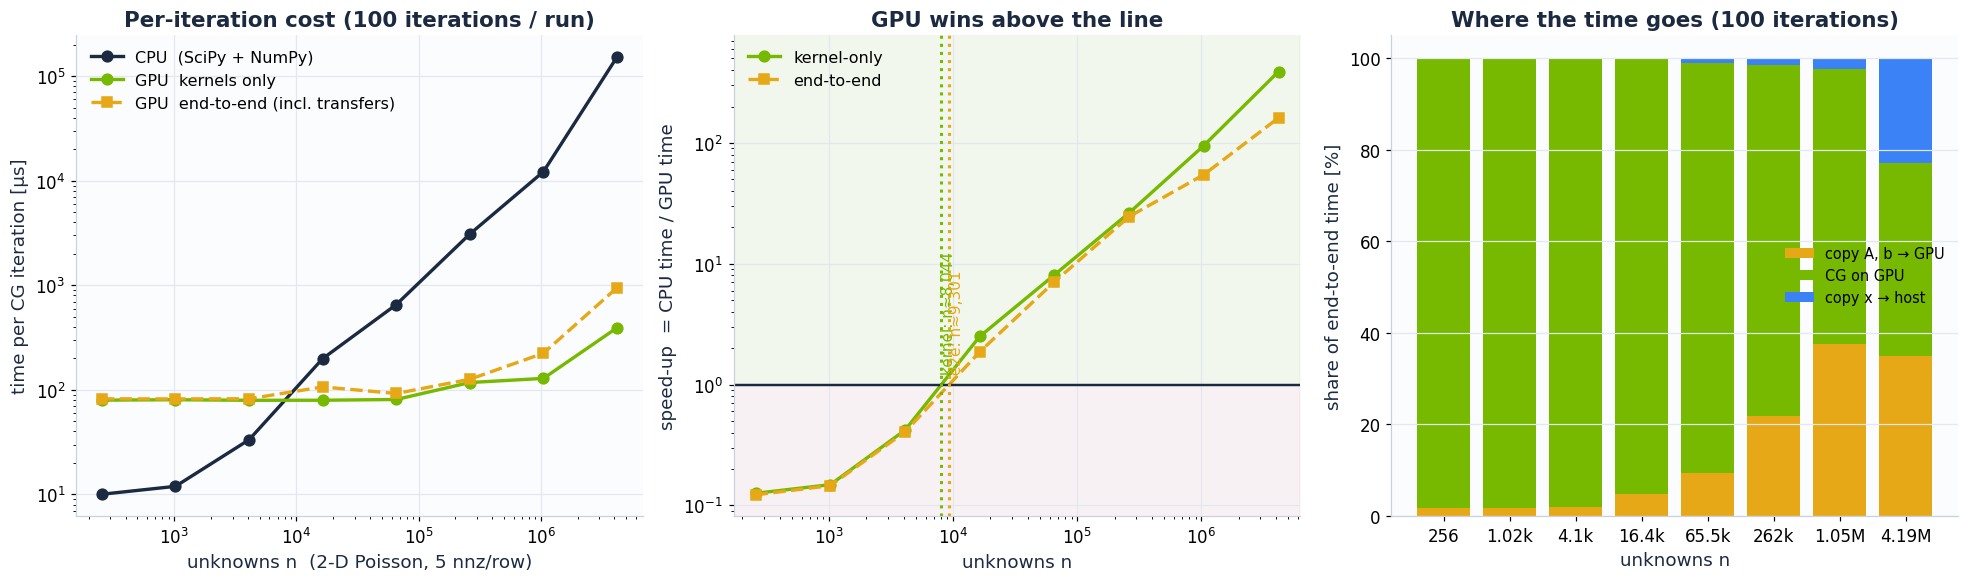

In [19]:
# ── Where does the GPU win? ──────────────────────────────────────────────────
d = CG_DF
x_k = crossover(d.n, d.speedup); x_e = crossover(d.n, d.speedup_e2e)
SUMMARY["cg_crossover"] = dict(kernel_only=x_k, end_to_end=x_e, iters=CG_ITERS)
def _lbl(c): return {"always": f"already at n ≤ {c['n']:,.0f}", "never": f"not within n ≤ {c['n']:,.0f}", "at": f"n ≈ {c['n']:,.0f}", "noisy": f"n ≈ {c['n']:,.0f} (noisy)"}[c["kind"]]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
ax = axes[0]
ax.plot(d.n, d.cpu_us_it, "-o", color=NAVY, label="CPU  (SciPy + NumPy)")
ax.plot(d.n, d.gpu_us_it, "-o", color=GREEN, label="GPU  kernels only")
ax.plot(d.n, d.e2e_us_it, "--s", color=ORANGE, label="GPU  end-to-end (incl. transfers)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("unknowns n  (2-D Poisson, 5 nnz/row)"); ax.set_ylabel("time per CG iteration [µs]")
ax.set_title(f"Per-iteration cost ({CG_ITERS} iterations / run)"); ax.legend()

ax = axes[1]
ax.plot(d.n, d.speedup, "-o", color=GREEN, label="kernel-only")
ax.plot(d.n, d.speedup_e2e, "--s", color=ORANGE, label="end-to-end")
ax.axhline(1, color=NAVY, lw=1.6)
ax.fill_between([d.n.min() / 1.5, d.n.max() * 1.5], 0.001, 1, color=RED, alpha=0.06); ax.fill_between([d.n.min() / 1.5, d.n.max() * 1.5], 1, 1e4, color=GREEN, alpha=0.07)
for c, col, nm in ((x_k, GREEN, "kernel"), (x_e, ORANGE, "e2e")):
    if c["kind"] == "at": ax.axvline(c["n"], color=col, ls=":", lw=2); ax.text(c["n"], 1.12, f" {nm}: n≈{c['n']:,.0f}", rotation=90, color=col, va="bottom", fontsize=10)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(d.n.min() / 1.5, d.n.max() * 1.5)
ax.set_ylim(min(d.speedup.min(), d.speedup_e2e.min(), 0.5) / 1.5, max(d.speedup.max(), 2) * 2)
ax.set_xlabel("unknowns n"); ax.set_ylabel("speed-up  = CPU time / GPU time"); ax.set_title("GPU wins above the line"); ax.legend(loc="upper left")

ax = axes[2]
parts = [d.h2d_s / d.e2e_s * 100, d.solve_cold_s / d.e2e_s * 100, d.d2h_s / d.e2e_s * 100]
ax.bar(range(len(d)), parts[0], color=ORANGE, label="copy A, b → GPU")
ax.bar(range(len(d)), parts[1], bottom=parts[0], color=GREEN, label="CG on GPU")
ax.bar(range(len(d)), parts[2], bottom=parts[0] + parts[1], color=BLUE, label="copy x → host")
ax.set_xticks(range(len(d))); ax.set_xticklabels([f"{human(v)}" for v in d.n]); ax.set_xlabel("unknowns n"); ax.set_ylabel("share of end-to-end time [%]")
ax.set_title(f"Where the time goes ({CG_ITERS} iterations)"); ax.legend(loc="center right", fontsize=9.5); ax.grid(axis="x", visible=False)
fig.tight_layout(); save_fig(fig, "C1_cg_scaling"); plt.show()

cards([("GPU wins · kernels only", _lbl(x_k), "CPU time ≥ GPU time from here"),
       ("GPU wins · end-to-end", _lbl(x_e), f"transfers included · {CG_ITERS} CG iterations"),
       ("Speed-up at largest n", f"{fx(d.speedup.iloc[-1])} / {fx(d.speedup_e2e.iloc[-1])}", f"kernel-only / end-to-end · n = {int(d.n.iloc[-1]):,}"),
       ("Small-n GPU latency", f"{d.gpu_us_it.iloc[0]:.0f} µs / iter", "≈ 7 launches + 2 host syncs, size-independent")])

In [20]:
#@title CG on the real SPD matrices (fixed iteration budget) { display-mode: "form" }
rows = []
for name, A_h in HOST.items():
    if not MAT_SPD.get(name): continue
    n = A_h.shape[0]; rg = np.random.default_rng(7)
    b_h = A_h.dot(rg.standard_normal(n)); box = {}
    t_cpu = time_wall(lambda: box.__setitem__("c", cg_cpu(A_h, b_h, REAL_CG_ITERS, 1e-8)), min_reps=1, max_reps=1, warmup=0)
    A_d = cpx_sparse.csr_matrix(A_h); b_d = cp.asarray(b_h); gsync()
    t_gpu = time_wall(lambda: box.__setitem__("g", cg_gpu(A_d, b_d, REAL_CG_ITERS, 1e-8)), min_reps=3, max_reps=5, warmup=1, sync=True)
    del A_d, b_d; cp.get_default_memory_pool().free_all_blocks()
    e2e = gpu_e2e(A_h, b_h, REAL_CG_ITERS, 1e-8, reps=2)
    tot = e2e["h2d"] + e2e["solve"] + e2e["d2h"]
    rows.append(dict(matrix=name, source=MAT_SRC[name], n=n, nnz=A_h.nnz, iters=box["c"][1], converged=bool(box["c"][2] <= 1e-8 * 1.01),
                     rel_residual=box["c"][2], cpu_s=t_cpu.median, gpu_s=t_gpu.median, h2d_s=e2e["h2d"], e2e_s=tot,
                     speedup=t_cpu.median / t_gpu.median, speedup_e2e=t_cpu.median / tot, xfer_share=(e2e["h2d"] + e2e["d2h"]) / tot,
                     cpu_ms_it=1e3 * t_cpu.median / box["c"][1], gpu_ms_it=1e3 * t_gpu.median / box["g"][1]))
    print(f"  {name:<10s} {box['c'][1]:>4} its  CPU {t_cpu.median:7.2f}s | GPU {t_gpu.median:6.3f}s | e2e {tot:6.3f}s | {t_cpu.median / t_gpu.median:6.1f}×")
REAL_CG_DF = pd.DataFrame(rows); save_df(REAL_CG_DF, "C2_cg_real_matrices"); SUMMARY["cg_real"] = REAL_CG_DF.to_dict("records")

  s3dkq4m2    500 its  CPU    1.72s | GPU  0.059s | e2e  0.059s |   29.4×
  ecology2    500 its  CPU    6.13s | GPU  0.062s | e2e  0.071s |   99.0×


,n,nnz,iters,converged,rel. residual,CPU s,GPU s,GPU e2e s,speed-up ×,e2e speed-up ×,transfer share
matrix,,,,,,,,,,,
s3dkq4m2,"90,449","4,820,891",500,False,2.3e-05,1.72,0.059,0.059,29.4,28.9,11%
ecology2,"1,000,000","4,996,000",500,False,2.8e-07,6.13,0.062,0.071,99.0,86.0,12%


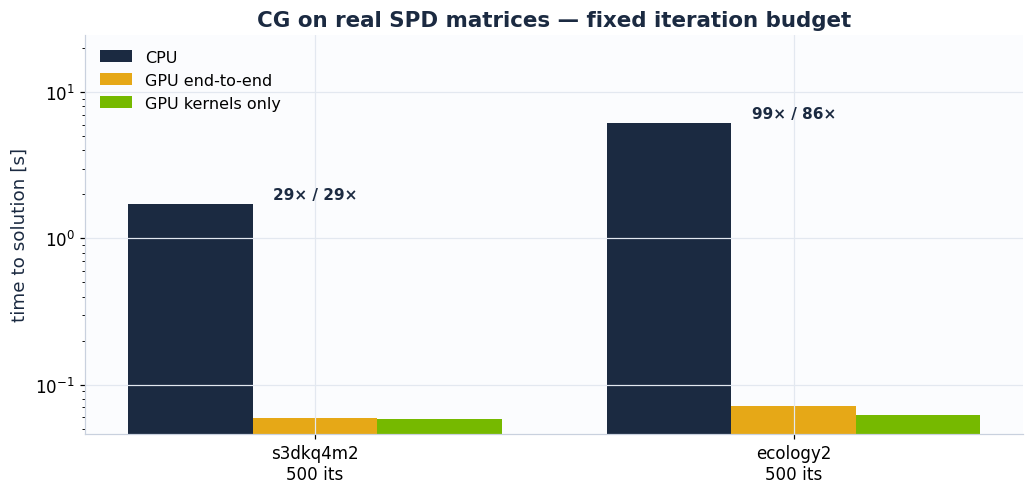

Iteration cap reached without converging means the plotted time is the cost of a fixed budget, not a time-to-tolerance.


In [21]:
# ── CG on the real matrices ──────────────────────────────────────────────────
t = REAL_CG_DF.set_index("matrix")
show_table(t[["n", "nnz", "iters", "converged", "rel_residual", "cpu_s", "gpu_s", "e2e_s", "speedup", "speedup_e2e", "xfer_share"]].rename(columns={
    "rel_residual": "rel. residual", "cpu_s": "CPU s", "gpu_s": "GPU s", "e2e_s": "GPU e2e s", "speedup": "speed-up ×", "speedup_e2e": "e2e speed-up ×", "xfer_share": "transfer share"}),
    {"n": "{:,}", "nnz": "{:,}", "rel. residual": "{:.1e}", "CPU s": "{:.2f}", "GPU s": "{:.3f}", "GPU e2e s": "{:.3f}", "speed-up ×": "{:.1f}", "e2e speed-up ×": "{:.1f}", "transfer share": "{:.0%}"},
    grad=["speed-up ×", "e2e speed-up ×"])
fig, ax = plt.subplots(figsize=(9.5, 4.6)); x = np.arange(len(t)); w = 0.26
ax.bar(x - w, t.cpu_s, w, color=NAVY, label="CPU"); ax.bar(x, t.e2e_s, w, color=ORANGE, label="GPU end-to-end"); ax.bar(x + w, t.gpu_s, w, color=GREEN, label="GPU kernels only")
for i, (s, s2) in enumerate(zip(t.speedup, t.speedup_e2e)): ax.text(i, t.cpu_s.iloc[i] * 1.08, f"{fx(s)} / {fx(s2)}", ha="center", fontweight="bold", color=NAVY)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels([f"{m}\n{int(it)} its" for m, it in zip(t.index, t.iters)]); ax.set_ylabel("time to solution [s]")
ax.set_title("CG on real SPD matrices — fixed iteration budget"); ax.legend(); ax.set_ylim(top=t.cpu_s.max() * 4)
fig.tight_layout(); save_fig(fig, "C2_cg_real"); plt.show()
print("Iteration cap reached without converging means the plotted time is the cost of a fixed budget, not a time-to-tolerance.")

# Wrap-up · key numbers

Auto-generated from this run. The narrative conclusions (what the numbers *mean* on this particular GPU) are written after looking at the exported results.

In [22]:
# ── Executive scorecard (auto-generated) ─────────────────────────────────────
best = GEMM_DF.groupby("precision").gflops.max() / 1e3
cards([("GPU", GPU_NAME[:28], f"CC {CC_MAJOR}.{CC_MINOR} · {MEM_GB:.0f} GB · BW {STREAM_BW:,.0f} GB/s measured"),
       ("GEMM · best precision", f"{best.max():,.1f} TFLOP/s", f"{best.idxmax()} · {best.max() / best.get('FP64', np.nan):.0f}× FP64" if "FP64" in best.index else best.idxmax()),
       ("SpMV · achieved BW", f"{SPMV_DF.gpu_GBs.min():,.0f}–{SPMV_DF.gpu_GBs.max():,.0f} GB/s", f"{SPMV_DF.pct_stream.min():.0f}–{SPMV_DF.pct_stream.max():.0f}% of measured STREAM"),
       ("SpMV · GPU vs 1 CPU core", f"{SPMV_DF.speedup.min():.1f}–{SPMV_DF.speedup.max():.1f}×", "kernel-only, cold L2"),
       ("CG · GPU starts winning", _lbl(x_k), f"end-to-end: {_lbl(x_e)}"),
       ("PCIe copy (pageable)", f"{H2D_BW:.1f} GB/s", "why end-to-end ≠ kernel-only")], accent=NAVY)
print("Caveats: CPU baseline = single-thread SciPy · datasheet peaks are boost-clock, dense · cloud GPUs may be shared/throttled · "
      + ("some matrices are SYNTHETIC stand-ins." if any("SYNTH" in s for s in MAT_SRC.values()) else "all matrices are the real SuiteSparse files."))

Caveats: CPU baseline = single-thread SciPy · datasheet peaks are boost-clock, dense · cloud GPUs may be shared/throttled · some matrices are SYNTHETIC stand-ins.


In [23]:
# ── Pack everything → hackathon_results.zip  (send this file back for the written analysis) ──
SUMMARY["config"] = dict(FAST=FAST, GEMM_SIZES=GEMM_SIZES, CG_GRIDS=CG_GRIDS, CG_ITERS=CG_ITERS, REAL_CG_ITERS=REAL_CG_ITERS,
                         matrices=[m["name"] for m in MATRICES], sources=MAT_SRC)
with open(OUT / "summary.json", "w") as f: json.dump(SUMMARY, f, indent=2, default=to_json_safe)
zip_path = shutil.make_archive("hackathon_results", "zip", OUT)
print("saved:")
for p in sorted(OUT.rglob("*")):
    if p.is_file(): print(f"  {str(p):<52s} {p.stat().st_size / 1024:8.1f} KB")
print(f"\n→ {zip_path}   ({os.path.getsize(zip_path) / 1024:.0f} KB)")
try:
    from google.colab import files
    files.download(zip_path)                      # Colab: triggers a browser download
except Exception:
    print("Not on Colab: copy hackathon_results.zip from the notebook's working directory.")

saved:
  hackathon_out/data/00_timing_pitfalls.csv                 0.2 KB
  hackathon_out/data/A1_gemm_accuracy.csv                   0.3 KB
  hackathon_out/data/A2_gemm_sweep.csv                      3.1 KB
  hackathon_out/data/B1_matrix_info.csv                     0.5 KB
  hackathon_out/data/B1_structure.json                    296.8 KB
  hackathon_out/data/B2_spmv_results.csv                    1.3 KB
  hackathon_out/data/C1_cg_sweep.csv                        2.5 KB
  hackathon_out/data/C2_cg_real_matrices.csv                0.6 KB
  hackathon_out/figures/00_timing_pitfalls.png             87.8 KB
  hackathon_out/figures/A1_gemm_accuracy.png               61.6 KB
  hackathon_out/figures/A2_gemm_throughput.png            224.1 KB
  hackathon_out/figures/B1_matrix_structure.png           191.1 KB
  hackathon_out/figures/B2_spmv_results.png               177.0 KB
  hackathon_out/figures/B3_roofline.png                   199.3 KB
  hackathon_out/figures/C1_cg_scaling.png              